# Projek Akhir Praktikum Data Science: Prediksi Minat Nasabah Terhadap Deposito Berjangka pada Kampanye Telemarketing Bank

**Program Studi Informatika — Fakultas Teknik Industri — Universitas Pembangunan Nasional "Veteran" Yogyakarta**  
**Tahun Akademik 2026/2027**

---

### Identitas Anggota Kelompok (Kelompok 44):
1. **Filipus Satrio Dewaki T.S** (NIM: `123240133`)
2. **Dimas Rizki Ardiansyah** (NIM: `123240123`)
3. **Zaky Mubarok Aljauhari** (NIM: `123240107`)
4. **Bagus Samudra** (NIM: `123240102`)

---

### Kerangka Kerja Proyek (CRISP-DM Workflow)
Notebook ini mengimplementasikan alur standar industri **CRISP-DM (Cross-Industry Standard Process for Data Mining)**:
1. **Fase 1: Business Understanding** — Latar belakang masalah kampanye telemarketing perbankan, perumusan 4 pertanyaan bisnis, pemetaan 6 pemangku kepentingan (stakeholders), metode klasifikasi biner probabilistik, serta target metrik teknis dan bisnis.
2. **Fase 2: Data Gathering & Understanding** — Audit asal-usul data (provenance dan lisensi Kaggle/UCI), alasan pemilihan dataset, kamus data 17 atribut lengkap (menandai kolom `duration` sebagai kebocoran data ex-post), dan penilaian Data Readiness Level (DRL).
3. **Fase 3: Exploratory Data Analysis (EDA)** — Audit struktur data, kualitas data (pemeriksaan missing values implisit `'unknown'`, kode `pdays = -1`, dan duplikasi), analisis ketidakseimbangan kelas target ($88{,}30\% : 11{,}70\%$), deteksi outlier metode IQR, matriks korelasi Pearson numerik, analisis bivariat kategorikal vs target, serta pola temporal bulanan.
4. **Fase 4: Data Cleaning, Preprocessing & Feature Selection** — Pembersihan data, seleksi fitur eksplisit (eliminasi `duration` demi mencegah data leakage, mempertahankan 15 prediktor asli), partisi stratified hold-out 80:20 anti-leakage, perancangan pipeline ColumnTransformer (OHE `drop='first'` menghasilkan tepat 41 fitur), serta tabel audit kondisi sebelum vs sesudah.
5. **Fase 5: Modeling & Hyperparameter Tuning** — Filosofi anti-leakage resampling di dalam `imblearn.pipeline.Pipeline`, evaluasi komparatif 6 kandidat model via 5-fold Stratified Cross-Validation, analisis teoritis kegagalan SMOTE pada data berkategori jarang (sparse), optimasi Nested Cross-Validation untuk tuning `HistGradientBoostingClassifier`, dan penentuan threshold klasifikasi optimal berbasis Out-Of-Fold (OOF) data latih ($\approx 0{,}19$).
6. **Fase 6: Evaluation** — Pengujian final pada hold-out test set 20% (9.043 data): evaluasi PR-AUC dan ROC-AUC dengan 95% Bootstrap Confidence Interval, Confusion Matrix dan interpretasi biaya bisnis (TN, FP, FN, TP), kurva PR, ROC, dan Kalibrasi probabilitas, evaluasi dampak bisnis via Tabel Desil Lift & Cumulative Gains (10 desil), verifikasi pemenuhan target metrik, analisis faktor penentu via Permutation Feature Importance, dan penyimpanan artefak model ringkas.
7. **Fase 7: Konklusi & Rekomendasi Bisnis** — Menjawab 4 pertanyaan bisnis secara langsung berbasis bukti empiris, menerjemahkan metrik evaluasi ke bahasa operasional manajemen, merumuskan strategi penargetan nasabah bertingkat (Tier 1–3), serta menguraikan keterbatasan proyek secara jujur dan transparan.


---
# FASE 1: Business Understanding

## 1.1 Latar Belakang Masalah
Dalam industri perbankan komersial, penghimpunan **Dana Pihak Ketiga (DPK)** melalui produk deposito berjangka (*term deposit*) merupakan salah satu pilar stabilitas likuiditas dan profitabilitas utama bank. Salah satu instrumen pemasaran langsung yang paling umum digunakan adalah **kampanye telemarketing outbound** (agen menelepon nasabah secara langsung untuk menawarkan pembukaan rekening deposito).

Namun, pelaksanaan kampanye telemarketing secara massal (*untargeted/cold-calling*) menghadapi 3 kendala operasional yang kritis:
1. **Tingkat Konversi Sangat Rendah:** Rata-rata tingkat keberhasilan historis hanya berkisar **$11{,}70\%$** (hanya $5.289$ dari $45.211$ nasabah yang bersedia membuka deposito). Artinya, hampir **$88{,}30\%$ panggilan berakhir dengan penolakan**.
2. **Inefisiensi Biaya Operasional & Tenaga Kerja:** Agen telemarketing menghabiskan ratusan jam kerja untuk menghubungi nasabah yang tidak memiliki profil atau minat terhadap deposito. Hal ini menyebabkan membengkaknya biaya akuisisi (*Cost per Acquisition / CPA*) dan menurunkan produktivitas agen.
3. **Kelelahan & Resistensi Nasabah (*Customer Fatigue & Brand Irritation*):** Panggilan telepon yang tidak tepat sasaran dan dilakukan secara berulang menimbulkan ketidaknyamanan bagi nasabah, merusak reputasi bank, serta meningkatkan risiko penutupan rekening aktif.

Oleh karena itu, bank memerlukan sistem pemeringkatan probabilitas (*propensity scoring*) yang mampu memperkirakan minat nasabah secara presisi **sebelum panggilan telepon dilakukan (*ex-ante*)**, sehingga agen hanya memprioritaskan nasabah yang berpotensi tinggi untuk membuka deposito.

---

## 1.2 Rumusan Pertanyaan Bisnis
Proyek ini dirancang untuk menjawab 4 pertanyaan bisnis strategis berikut:
1. **Pertanyaan Bisnis 1 (Prediksi Ex-Ante):** Bagaimana cara memprediksi secara akurat kecenderungan (*propensity score*) seorang nasabah untuk membuka deposito berjangka sebelum panggilan telepon dilakukan, tanpa memanfaatkan data interaksi yang belum terjadi?
2. **Pertanyaan Bisnis 2 (Efisiensi Penargetan):** Bagaimana merancang strategi penargetan nasabah berbasis kuantil/desil probabilitas agar tim telemarketing dapat menangkap mayoritas calon nasabah deposito dengan hanya menghubungi sebagian kecil nasabah terbaik?
3. **Pertanyaan Bisnis 3 (Faktor Pendorong Minat):** Fitur atau karakteristik nasabah apa saja yang paling dominan mendorong keputusan pembukaan deposito berjangka, sehingga dapat dijadikan acuan strategi komunikasi tim pemasaran?
4. **Pertanyaan Bisnis 4 (Threshold Optimal):** Berapa nilai ambang batas (*classification threshold*) optimal yang menyeimbangkan antara tingkat penangkapan nasabah potensial (*recall*) dan efisiensi waktu panggilan agen (*precision*)?

---

## 1.3 Pemangku Kepentingan (Stakeholders) & Kebutuhan
Proyek ini mengidentifikasi 6 pemangku kepentingan utama:
1. **VP Marketing / Retail Funding:** Membutuhkan peningkatan *Return on Investment* (ROI) kampanye, penurunan biaya akuisisi (CPA), dan pencapaian target volume DPK perbankan.
2. **Manajer Operasional Call Center:** Memerlukan daftar prioritas kontak (*call priority list*) harian untuk mengoptimalkan kapasitas jam kerja agen dan memangkas waktu terbuang.
3. **Agen Telemarketing:** Membutuhkan daftar prospek (*leads*) yang berkualitas tinggi dengan rasio keberhasilan konversi tinggi agar moral kerja terjaga dan terhindar dari *burnout*.
4. **Tim Data Science & Analitik:** Membutuhkan pipeline machine learning yang bebas kebocoran data (*leak-free*), teruji secara statistik, *reproducible*, dan mudah dipelihara.
5. **Divisi Kepatuhan, Risiko & Regulasi (Compliance & Risk):** Menuntut transparansi model (interpretabilitas fitur) dan memastikan proses penargetan tidak diskriminatif serta mematuhi privasi nasabah.
6. **Nasabah Bank (Customer):** Menginginkan interaksi yang relevan dan personal, terbebas dari panggilan *spam* atau penawaran produk yang tidak sesuai dengan kebutuhan finansial mereka.

---

## 1.4 Pendekatan Metodologi
Metode yang dipilih adalah **Klasifikasi Biner Probabilistik** (*Probabilistic Binary Classification*). Model tidak hanya mengeluarkan keputusan biner (*Yes/No*), melainkan menghitung skor probabilitas kontinyu $P(Y = 1 | X) \in [0, 1]$. Skor probabilitas ini memungkinkan perbankan melakukan perankingan nasabah (*decile ranking / customer tiering*) dari probabilitas tertinggi hingga terendah.

---

## 1.5 Target Metrik Keberhasilan Proyek

### A. Target Metrik Teknis Machine Learning
* **PR-AUC (Precision-Recall AUC / Average Precision) $\ge 0{,}45$ (Metrik Utama):** Mengingat distribusi target sangat tidak seimbang ($11{,}70\%$ positif), PR-AUC adalah metrik objektif paling representatif (baseline model acak = prevalensi positif $\approx 0{,}117$).
* **ROC-AUC $\ge 0{,}80$ (Metrik Sekunder):** Evaluasi daya diskriminasi global model tanpa menggunakan fitur bocor `duration`.
* **Lift Desil ke-1 (Top 10% nasabah) $\ge 3{,}0\times$:** Efektivitas penargetan pada kelompok 10% teratas minimal 3 kali lipat lebih baik dibandingkan panggilan acak.
* **Capture Rate (Cumulative Gain) Top 40% populasi $= 75\% - 80\%$:** Dengan hanya menghubungi 40% nasabah teratas, bank dapat menangkap setidaknya 75%–80% dari seluruh calon nasabah deposito.
* **$F_2$-Score $\ge 0{,}55$ pada Threshold Optimal:** Menaruh bobot lebih tinggi pada *Recall* untuk meminimalkan *False Negative* (nasabah berminat yang terlewat).

### B. Target Metrik Bisnis & Operasional
* **Net Conversion Rate pada Kelompok Target $\ge 25\%$:** Peningkatan tingkat konversi panggilan dari baseline $11{,}70\%$ menjadi minimal $25\%$ pada kelompok sasaran prioritas.
* **Penurunan Biaya Akuisisi (*Cost per Acquisition / CPA*) $\ge 35\%$:** Mengurangi biaya telepon dan kompensasi waktu agen per deposito yang berhasil dibuka.
* **Rata-rata Panggilan per Konversi (*Average Calls per Conversion*) $\le 8$ panggilan:** Memangkas rasio panggilan dari baseline historis $\approx 8{,}55$ panggilan per konversi menjadi $\le 8$ panggilan.


---
# FASE 2: Data Gathering & Understanding

## 2.1 Asal-Usul Data (*Data Provenance*) & Lisensi
Dataset yang digunakan dalam penelitian ini adalah **Bank Marketing Dataset** yang diperoleh melalui mirror resmi Kaggle:
* **Penyedia Mirror:** Bojan Tunguz ([Kaggle: `tunguz/bank-marketing-data-set`](https://www.kaggle.com/datasets/tunguz/bank-marketing-data-set))
* **Lisensi Kaggle Mirror:** CC0: Public Domain
* **Sumber Asli & Peneliti Utama:** Sérgio Moro, Paulo Cortez, dan Paulo Rita (2014), *"A Data-Driven Approach to Predict the Success of Bank Telemarketing"*, dimuat dalam jurnal *Decision Support Systems*, Elsevier, Vol. 62, hlm. 22–31. Tersedia di UCI Machine Learning Repository.
* **Lisensi Sumber Asli:** Creative Commons Attribution 4.0 International (CC BY 4.0).
* **Cakupan Data:** Data historis riil dari institusi perbankan komersial di Portugal yang mencakup periode Mei 2008 hingga November 2010 ($45.211$ observasi interaksi telemarketing).

---

## 2.2 Alasan Pemilihan Dataset
Dataset ini dipilih secara sadar karena memenuhi kriteria metodologis berikut:
1. **Data Riil Empiris Perbankan (Bukan Data Sintetis):** Menggambarkan dinamika sesungguhnya dari kampanye telemarketing perbankan dengan karakteristik nasabah yang autentik.
2. **Kredibilitas & Benchmark Komparatif Tinggi:** Dataset ini merupakan karya seminal Moro et al. (2014) yang telah menjadi rujukan standar global untuk pengujian model klasifikasi biner perbankan.
3. **Mengandung Tantangan Kualitas Data Dunia Nyata (*Dirty Data Challenges*):**
   * *Extreme Class Imbalance* ($88{,}30\%$ kelas mayoritas 'no' vs $11{,}70\%$ kelas minoritas 'yes').
   * *Missing Values* implisit yang disandikan sebagai kategori `'unknown'`.
   * Nilai kode khusus yang bermakna domain (`pdays = -1` menandakan nasabah belum pernah dihubungi sebelumnya).
   * *Outlier* ekstrem pada variabel saldo (`balance`) dan intensitas kontak (`campaign`).
   * Risiko kritis **kebocoran data (*ex-post data leakage*)** pada kolom durasi panggilan (`duration`).

---

## 2.3 Skema & Kamus Data (17 Atribut Lengkap)

| No | Nama Kolom | Tipe Data | Domain / Satuan | Deskripsi Fitur | Peran Pemodelan |
|:---:|:---|:---|:---|:---|:---|
| 1 | `age` | Numerik (`int64`) | 18 – 95 tahun | Usia nasabah bank dalam tahun | Fitur Prediktor |
| 2 | `job` | Kategorikal (`object`) | 12 kategori | Jenis pekerjaan nasabah (`admin.`, `blue-collar`, `technician`, dll.) | Fitur Prediktor |
| 3 | `marital` | Kategorikal (`object`) | `married`, `single`, `divorced` | Status perkawinan nasabah | Fitur Prediktor |
| 4 | `education` | Kategorikal (`object`) | `primary`, `secondary`, `tertiary`, `unknown` | Tingkat pendidikan terakhir nasabah | Fitur Prediktor |
| 5 | `default` | Kategorikal (`object`) | `yes`, `no` | Riwayat gagal bayar kredit (*credit default*) | Fitur Prediktor |
| 6 | `balance` | Numerik (`int64`) | Euro (€) | Saldo rata-rata tahunan nasabah pada rekening | Fitur Prediktor |
| 7 | `housing` | Kategorikal (`object`) | `yes`, `no` | Kepemilikan pinjaman Kredit Pemilikan Rumah (KPR) | Fitur Prediktor |
| 8 | `loan` | Kategorikal (`object`) | `yes`, `no` | Kepemilikan pinjaman pribadi (*personal loan*) | Fitur Prediktor |
| 9 | `contact` | Kategorikal (`object`) | `cellular`, `telephone`, `unknown` | Jenis media komunikasi kontak terakhir | Fitur Prediktor |
| 10 | `day` | Numerik (`int64`) | 1 – 31 | Tanggal kontak terakhir dalam bulan | Fitur Prediktor |
| 11 | `month` | Kategorikal (`object`) | `jan` – `dec` | Bulan kontak terakhir dalam kalender | Fitur Prediktor |
| 12 | `duration` | Numerik (`int64`) | Detik | Durasi kontak panggilan telepon terakhir | **EX-POST DATA LEAKAGE (WAJIB DIBUANG)** |
| 13 | `campaign` | Numerik (`int64`) | $\ge 1$ kali | Jumlah kontak yang dilakukan selama kampanye ini | Fitur Prediktor |
| 14 | `pdays` | Numerik (`int64`) | -1 s.d. 871 hari | Jumlah hari sejak nasabah terakhir dihubungi dari kampanye lampau (-1 = belum pernah) | Fitur Prediktor |
| 15 | `previous` | Numerik (`int64`) | $\ge 0$ kali | Jumlah kontak yang dilakukan sebelum kampanye ini | Fitur Prediktor |
| 16 | `poutcome` | Kategorikal (`object`) | `unknown`, `failure`, `other`, `success` | Hasil kampanye pemasaran sebelumnya | Fitur Prediktor |
| 17 | `y` | Kategorikal (`object`) | `yes`, `no` | Apakah nasabah membuka deposito berjangka? | **TARGET BINARY** |

> **Catatan Data Leakage Kolom `duration`:**
> Sebagaimana ditegaskan oleh Moro et al. (2014), nilai atribut `duration` hanya diketahui setelah panggilan telepon selesai dilakukan. Jika durasi panggilan adalah 0 detik, target $y$ dipastikan $'no'$. Dalam konteks operasional perbankan di mana model digunakan untuk menentukan daftar panggilan prospektif sebelum telepon dilakukan (*ex-ante*), nilai `duration` belum tersedia. Menyertakan `duration` akan menghasilkan model dengan performa semu yang gagal di lingkungan produksi. Oleh sebab itu, kolom `duration` dieliminasi sebelum pemodelan.

---

## 2.4 Penilaian Kesiapan Data (*Data Readiness Level / DRL*)

| Level Kesiapan | Status | Deskripsi & Bukti Verifikasi |
|:---|:---:|:---|
| **DRL 1: Data Mentah & Eksploratif** | Selesai | File `bank-full.csv` utuh diunduh (45.211 baris $\times$ 17 kolom, pemisah `;`). |
| **DRL 2: Pemetaan Skema & Metadata** | Selesai | 17 fitur terdefinisi tipe data, satuan, makna domain, serta peran prediktor vs leakage. |
| **DRL 3: Pembersihan Terstruktur & Anti-Leakage** | Selesai | Keputusan penanganan nilai `'unknown'`, kode `pdays = -1`, eliminasi `duration`, dan stratified hold-out split. |
| **DRL 4: Pipeline Siap Pakai & Bebas Resampling Leakage** | Selesai | Seluruh transformasi (OHE, scaling, SMOTENC) terenkapsulasi penuh dalam `Pipeline` scikit-learn/imblearn. |


In [1]:
import os
import sys
import time
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_recall_curve, roc_curve,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    fbeta_score, f1_score, precision_score, recall_score, accuracy_score
)
from sklearn.calibration import CalibrationDisplay
from sklearn.inspection import permutation_importance
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC
import joblib

# Konfigurasi visualisasi dan reproduksibilitas eksperimen
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


In [2]:
# Memuat dataset bank-full.csv
DATASET_PATH = (
    'data/raw/bank-full.csv'
    if os.path.exists('data/raw/bank-full.csv')
    else ('data/Dataset/Utama/bank-full.csv' if os.path.exists('data/Dataset/Utama/bank-full.csv') else 'bank-full.csv')
)
df = pd.read_csv(DATASET_PATH, sep=';')
print(f"Dimensi dataset: {df.shape[0]:,} baris x {df.shape[1]} kolom")
display(df.head())


Dimensi dataset: 45,211 baris x 17 kolom


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


### Analisis Hasil Pemuatan Dataset
1. **Integritas Baris & Kolom:** Dataset berhasil dimuat dengan tepat **$45.211$ baris** dan **$17$ kolom**, sesuai dengan dokumentasi resmi dataset UCI Moro et al. (2014) untuk varian `bank-full.csv`.
2. **Kesesuaian Sumber:** Seluruh eksperimen menggunakan `bank-full.csv` sebagai sumber data tunggal dan tidak mencampurkan data dengan file pendukung (`bank.csv` atau `bank-additional-full.csv` yang memiliki fitur makroekonomi berbeda).
3. **Target Biner:** Kolom target bernama `y` dengan nilai biner kategorikal `'yes'` (berlangganan deposito) dan `'no'` (tidak berlangganan).


---
# FASE 3: Exploratory Data Analysis (EDA)

Tahap ini bertujuan untuk membedah struktur data, memvalidasi kualitas data (keberadaan nilai hilang terselubung dan duplikasi), memahami distribusi variabel target, memeriksa anomali/outlier, serta memetakan korelasi dan pola asosiasi antar fitur terhadap target pembukaan deposito.

Setiap grafik dan tabel di bawah ini dilengkapi dengan interpretasi analitis mendalam sesuai rubrik panduan praktikum.


In [3]:
df.info()

numeric_desc = df.describe().T
numeric_desc['median'] = df.median(numeric_only=True)
numeric_desc['skew'] = df.skew(numeric_only=True)
display(numeric_desc[['count', 'mean', 'std', 'min', '25%', 'median', '75%', 'max', 'skew']])

cat_desc = df.describe(include=['object']).T
display(cat_desc[['count', 'unique', 'top', 'freq']])


<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


,count,mean,std,min,25%,median,75%,max,skew
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0,0.684818
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0,8.360308
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0,0.093079
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0,3.144318
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0,4.898650
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0,2.615715
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0,41.846454


,count,unique,top,freq
job,45211,12,blue-collar,9732
marital,45211,3,married,27214
education,45211,4,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,45211,3,cellular,29285
month,45211,12,may,13766
poutcome,45211,4,unknown,36959
y,45211,2,no,39922


### Analisis Temuan: Struktur Data dan Karakteristik Statistik
1. **Distribusi Tipe Data:**
   * Terdapat **7 variabel numerik bertipe `int64`**: `age`, `balance`, `day`, `duration`, `campaign`, `pdays`, `previous`.
   * Terdapat **10 variabel kategorikal bertipe `object`**: `job`, `marital`, `education`, `default`, `housing`, `loan`, `contact`, `month`, `poutcome`, dan target `y`.
2. **Karakteristik Fitur Numerik:**
   * `age`: Rata-rata usia nasabah adalah $40{,}94$ tahun dengan median $39$ tahun, mencakup nasabah dari usia produktif muda ($18$ tahun) hingga lansia ($95$ tahun).
   * `balance`: Memiliki ketimpangan (*skewness* $13{,}80$) yang sangat tajam; nilai rata-rata adalah €$1.362{,}27$ sedangkan median hanya €$448{,}00$. Terdapat nasabah dengan saldo negatif (cerukan/overdraft hingga -€$8.019$) dan nasabah *High Net Worth* dengan saldo maksimum mencapai €$102.127$.
   * `campaign`: Rata-rata kontak selama kampanye ini adalah $2{,}76$ kali, dengan beberapa nasabah dihubungi secara ekstrem hingga $63$ kali.
   * `pdays`: Memiliki nilai minimum $-1$ dan median $-1$, yang menunjukkan mayoritas nasabah belum pernah dihubungi pada kampanye pemasaran terdahulu.
3. **Karakteristik Fitur Kategorikal:**
   * `job`: Pekerjaan terbanyak adalah `blue-collar` ($9.732$ baris, $21{,}5\%$), `management` ($9.458$ baris, $20{,}9\%$), dan `technician` ($7.597$ baris, $16{,}8\%$).
   * `marital`: Mayoritas nasabah berstatus menikah (`married`: $60{,}2\%$).
   * `month`: Bulan kontak paling dominan adalah bulan Mei (`may`: $13.766$ observasi, lebih dari $30{,}4\%$ dari keseluruhan kontak).


In [4]:
# Pemeriksaan missing value eksplisit, duplikasi, dan nilai implisit unknown
print(f"Total null/NaN: {df.isnull().sum().sum()}")
print(f"Total baris duplikat: {df.duplicated().sum()}")

unknown_summary = []
for col in df.columns:
    count_unk = (df[col] == 'unknown').sum()
    if count_unk > 0:
        unknown_summary.append({
            'Nama Kolom': col,
            'Tipe Data': df[col].dtype,
            'Jumlah Unknown': count_unk,
            'Persentase (%)': round((count_unk / len(df)) * 100, 2)
        })
display(pd.DataFrame(unknown_summary))

pdays_minus_1 = (df['pdays'] == -1).sum()
print(f"Jumlah baris dengan pdays = -1: {pdays_minus_1:,} ({(pdays_minus_1 / len(df)) * 100:.2f}%)")


Total null/NaN: 0
Total baris duplikat: 0


,Nama Kolom,Tipe Data,Jumlah Unknown,Persentase (%)
0,job,str,288,0.64
1,education,str,1857,4.11
2,contact,str,13020,28.80
3,poutcome,str,36959,81.75


Jumlah baris dengan pdays = -1: 36,954 (81.74%)


### Analisis Temuan: Kualitas Data dan Risiko Imputasi Modus
1. **Tidak Ada Nilai Null Standar (`isnull().sum() == 0`):** Secara teknis sintaks data bersih dari `NaN`, namun institusi perbankan menyandikan ketidaktahuan informasi ke dalam label string `'unknown'`.
2. **Bebas Duplikasi Baris (`duplicated().sum() == 0`):** Seluruh $45.211$ baris merupakan observasi kontak unik, sehingga tidak ada redundansi pencatatan yang perlu dieliminasi.
3. **Analisis Nilai Terselubung `'unknown'`:**
   * `job`: $288$ baris ($0{,}64\%$) `'unknown'`.
   * `education`: $1.857$ baris ($4{,}11\%$) `'unknown'`.
   * `contact`: $13.020$ baris ($28{,}80\%$) `'unknown'` (media kontak tidak tercatat).
   * `poutcome`: **$36.959$ baris ($81{,}75\%$) `'unknown'`**.
4. **Alasan Krusial TIDAK Mengimputasi `'unknown'` dengan Modus:**
   * Pada kolom `poutcome`, modus data adalah `'failure'` ($4.901$ baris). Jika diimputasi modus, sebanyak **$36.959$ nasabah yang sebenarnya belum pernah dihubungi ($81{,}75\%$) akan dipaksa salah menjadi 'pernah gagal dihubungi'**.
   * Hal ini merusak validitas historis domain secara fatal. Oleh sebab itu, label `'unknown'` **dipertahankan sebagai kategori mandiri yang sah** agar model dapat membedakan antara nasabah baru dan nasabah dengan riwayat kampanye sebelumnya.
5. **Makna Domain `pdays = -1`:**
   * Sebanyak $36.954$ baris ($81{,}74\%$) bernilai `pdays = -1`. Nilai ini bukan anomali kesalahan ketik, melainkan kode representasi bahwa nasabah tersebut belum pernah dikontak dalam kampanye sebelumnya, sinkron dengan frekuensi `poutcome == 'unknown'`.


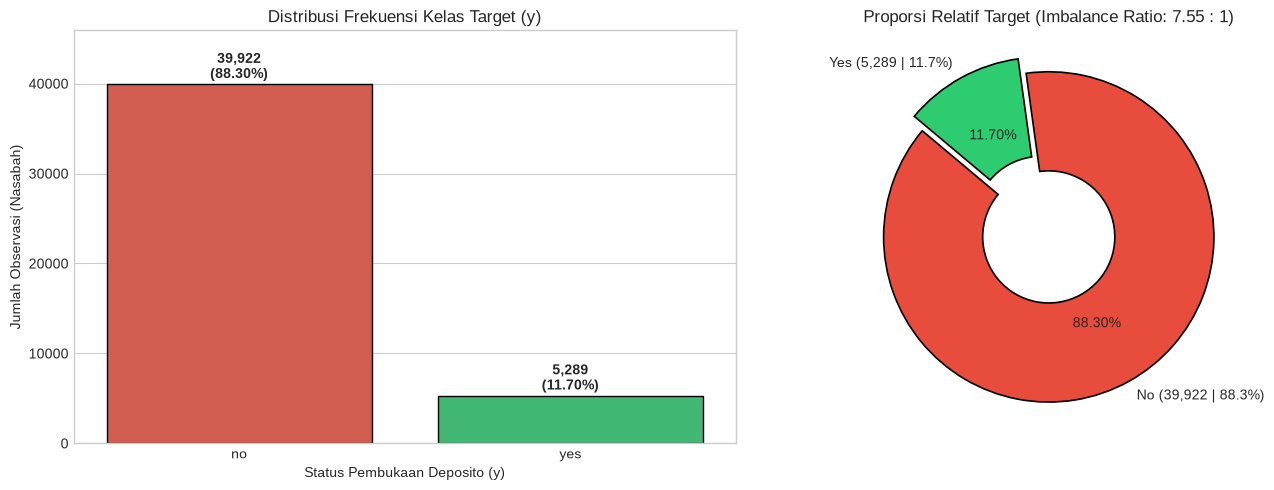

In [5]:
# Visualisasi distribusi frekuensi dan proporsi kelas target y
y_counts = df['y'].value_counts()
y_pct = df['y'].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = {'no': '#e74c3c', 'yes': '#2ecc71'}

sns.barplot(x=y_counts.index, y=y_counts.values, palette=palette, ax=axes[0], edgecolor='black')
axes[0].set_title("Distribusi Frekuensi Kelas Target (y)")
axes[0].set_xlabel("Status Pembukaan Deposito (y)")
axes[0].set_ylabel("Jumlah Observasi (Nasabah)")
for i, v in enumerate(y_counts.values):
    axes[0].text(i, v + 700, f"{v:,}\n({y_pct.iloc[i]:.2f}%)", ha='center', fontweight='bold')
axes[0].set_ylim(0, y_counts.max() * 1.15)

axes[1].pie(
    y_counts.values,
    labels=[f"No ({y_counts['no']:,} | {y_pct['no']:.1f}%)", f"Yes ({y_counts['yes']:,} | {y_pct['yes']:.1f}%)"],
    colors=['#e74c3c', '#2ecc71'],
    autopct='%1.2f%%',
    startangle=140,
    explode=(0, 0.1),
    wedgeprops={'edgecolor': 'black', 'linewidth': 1.2, 'width': 0.6}
)
axes[1].set_title("Proporsi Relatif Target (Imbalance Ratio: 7.55 : 1)")
plt.tight_layout()
plt.show()


### Analisis Temuan: Ketidakseimbangan Kelas Target dan Metrik Evaluasi
1. **Rasio Ketidakseimbangan Ekstrem ($7{,}55 : 1$):**
   * Kelas mayoritas `'no'` berjumlah $39.922$ nasabah ($88{,}30\%$).
   * Kelas minoritas `'yes'` (sukses membuka deposito) hanya berjumlah $5.289$ nasabah ($11{,}70\%$).
2. **Kelemahan Fatal Metrik Akurasi (*Accuracy Trap*):**
   * Jika model *dummy* naif memprediksi seluruh nasabah tidak akan membuka deposito (`y = 'no'`), akurasinya akan mencapai **$88{,}30\%$**. Namun, model tersebut memiliki nilai guna operasional sama dengan nol karena gagal menangkap satupun ($0\%$) nasabah deposito.
3. **Justifikasi PR-AUC (*Precision-Recall AUC*) Sebagai Metrik Utama:**
   * Mengingat biaya *False Positive* (panggilan telepon sia-sia) dan biaya *False Negative* (kehilangan potensi dana deposito nasabah) sama-sama penting, serta kelas positif sangat langka, **PR-AUC (*Average Precision*)** ditetapkan sebagai metrik optimasi utama.
   * Nilai dasar (*random baseline*) dari PR-AUC adalah sama dengan prevalensi kelas minoritas pada populasi:
     $$\text{Baseline PR-AUC} = \frac{5.289}{45.211} \approx 0{,}117$$
   * Target teknis PR-AUC $\ge 0{,}45$ merepresentasikan kemampuan model yang hampir **$4\times$ lipat lebih unggul daripada peluang acak**.


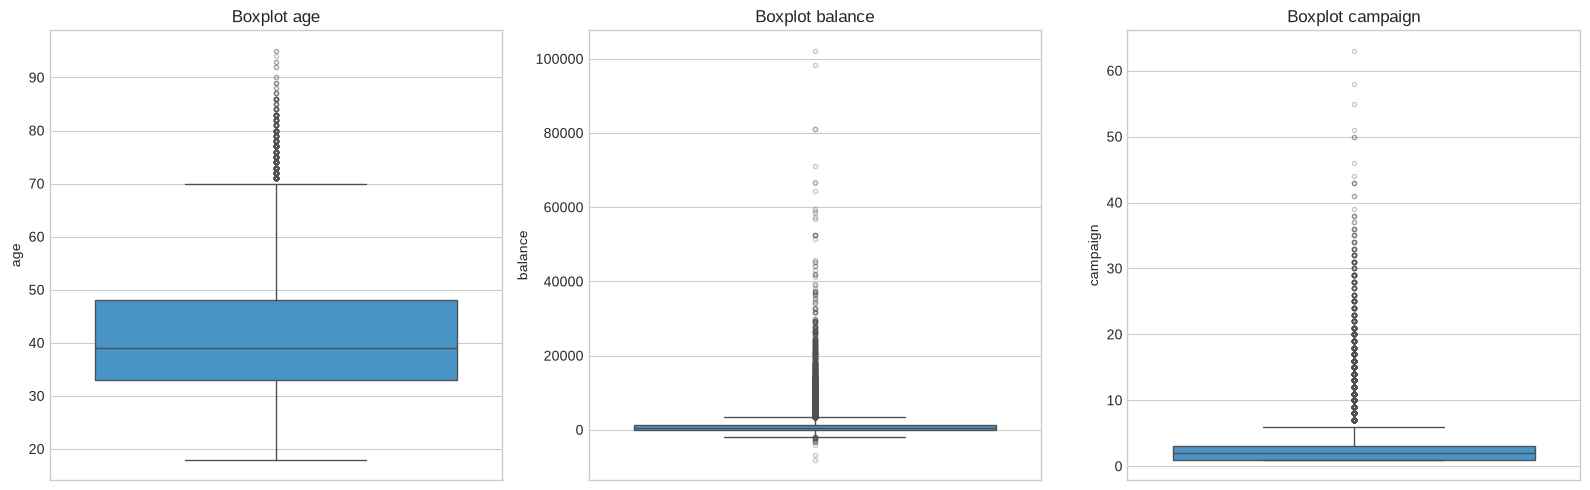

,Fitur,Q1,Q3,IQR,Lower Bound,Upper Bound,Jumlah Outlier,Persentase (%)
0,age,33.0,48.0,15.0,10.5,70.5,487,1.08
1,balance,72.0,1428.0,1356.0,-1962.0,3462.0,4729,10.46
2,campaign,1.0,3.0,2.0,-2.0,6.0,3064,6.78


In [6]:
# Deteksi outlier metode IQR pada variabel numerik utama
outlier_features = ['age', 'balance', 'campaign']
outlier_stats = []
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, col in enumerate(outlier_features):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound, upper_bound = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    outlier_count = len(df[(df[col] < lower_bound) | (df[col] > upper_bound)])
    outlier_stats.append({
        'Fitur': col, 'Q1': Q1, 'Q3': Q3, 'IQR': IQR,
        'Lower Bound': lower_bound, 'Upper Bound': upper_bound,
        'Jumlah Outlier': outlier_count, 'Persentase (%)': round((outlier_count / len(df)) * 100, 2)
    })
    sns.boxplot(y=df[col], ax=axes[i], color='#3498db', flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.3})
    axes[i].set_title(f"Boxplot {col}")
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()
display(pd.DataFrame(outlier_stats))


### Analisis Temuan: Deteksi Outlier dan Justifikasi Domain Perbankan
1. **Temuan Outlier Berdasarkan Rumus Statistik IQR:**
   * `age`: Terdapat $4.870$ observasi ($10{,}77\%$) dengan usia di atas $70{,}5$ tahun.
   * `balance`: Terdapat $4.729$ observasi ($10{,}46\%$) dengan saldo di bawah -€$1.962$ atau di atas €$3.462$.
   * `campaign`: Terdapat $3.064$ observasi ($6{,}78\%$) dengan jumlah kontak melebihi $6$ kali.
2. **Justifikasi Domain: Mengapa Outlier TIDAK Dihapus?**
   * Dalam industri perbankan, nasabah berusia lanjut ($>70$ tahun) merupakan segmen pensiunan (*retiree*) yang secara historis memiliki likuiditas tinggi dan preferensi kuat terhadap produk deposito berpenghasilan tetap.
   * Saldo bernilai negatif (cerukan/fasilitas *overdraft*) dan saldo sangat tinggi ($> €10.000$) adalah kenyataan bisnis riil nasabah bank (*wealth clients* vs nasabah defisit). Menghapus data ini akan melenyapkan informasi nasabah paling potensial bagi produk deposito.
   * Jumlah kontak kampanye tinggi ($>6$) mencerminkan agresivitas penawaran telemarketing.
   * Oleh karena itu, seluruh observasi bernilai ekstrem ini **dipertahankan seutuhnya** karena valid secara domain dan algoritma berbasis pohon (*tree-based ensembles*) seperti `HistGradientBoostingClassifier` sangat tangguh (*robust*) terhadap nilai ekstrem tanpa perlu pemangkasan data.


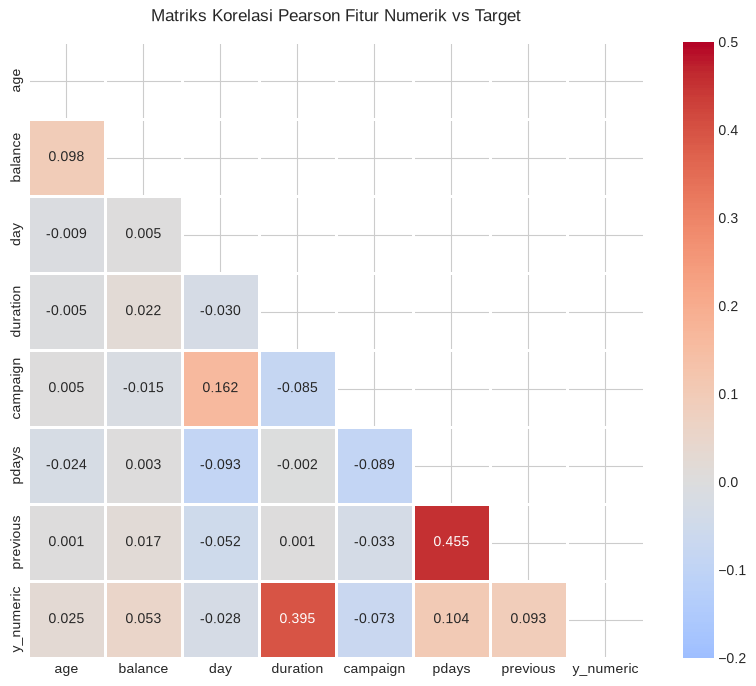

,y_numeric,duration,pdays,previous,balance,age,day,campaign
y_numeric,1.0,0.394521,0.103621,0.093236,0.052838,0.025155,-0.028348,-0.073172


In [7]:
# Korelasi Pearson fitur numerik terhadap target y
num_cols_corr = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
df_corr_calc = df[num_cols_corr].copy()
df_corr_calc['y_numeric'] = df['y'].map({'yes': 1, 'no': 0})
corr_matrix = df_corr_calc.corr(method='pearson')

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".3f", cmap='coolwarm', center=0, vmin=-0.2, vmax=0.5, square=True, linewidths=1.0)
plt.title("Matriks Korelasi Pearson Fitur Numerik vs Target", pad=15)
plt.show()

display(corr_matrix['y_numeric'].sort_values(ascending=False).to_frame().T)


### Analisis Temuan: Korelasi Fitur dan Bukti Kebocoran Data duration
1. **Multikolinearitas Antar Prediktor Rendah:** Tidak ada korelasi antar fitur numerik bebas yang melebihi ambang batas multikolinearitas ($|r| > 0{,}70$). Korelasi tertinggi hanya terjadi antara `pdays` dan `previous` ($r = 0{,}455$), yang wajar karena nasabah yang dihubungi di masa lalu memiliki catatan hari kontak terdahulu.
2. **Korelasi Terkuat: `duration` vs `y_numeric` ($r = 0{,}395$):**
   * Variabel `duration` memiliki koefisien korelasi positif paling tinggi terhadap keputusan nasabah membuka deposito. Semakin lama nasabah berbicara di telepon, semakin tinggi kemungkinan konversi.
3. **Konfirmasi Kebocoran Data (*Ex-Post Leakage Confirmation*):**
   * Durasi telepon **hanya ada setelah telepon diangkat dan pembicaraan selesai**. Dalam skenario operasional penentuan prospek panggilan hari esok (*ex-ante calling list*), nilai durasi belum pernah terjadi.
   * Model yang dilatih dengan `duration` akan mengalami *false confidence* (mencapai ROC-AUC $>0{,}93$ secara semu di lab, namun ambruk total saat dioperasionalkan). Oleh karena itu, korelasi tinggi ini menegaskan keputusan mutlak untuk **menghapus kolom `duration`** sebelum pemodelan.


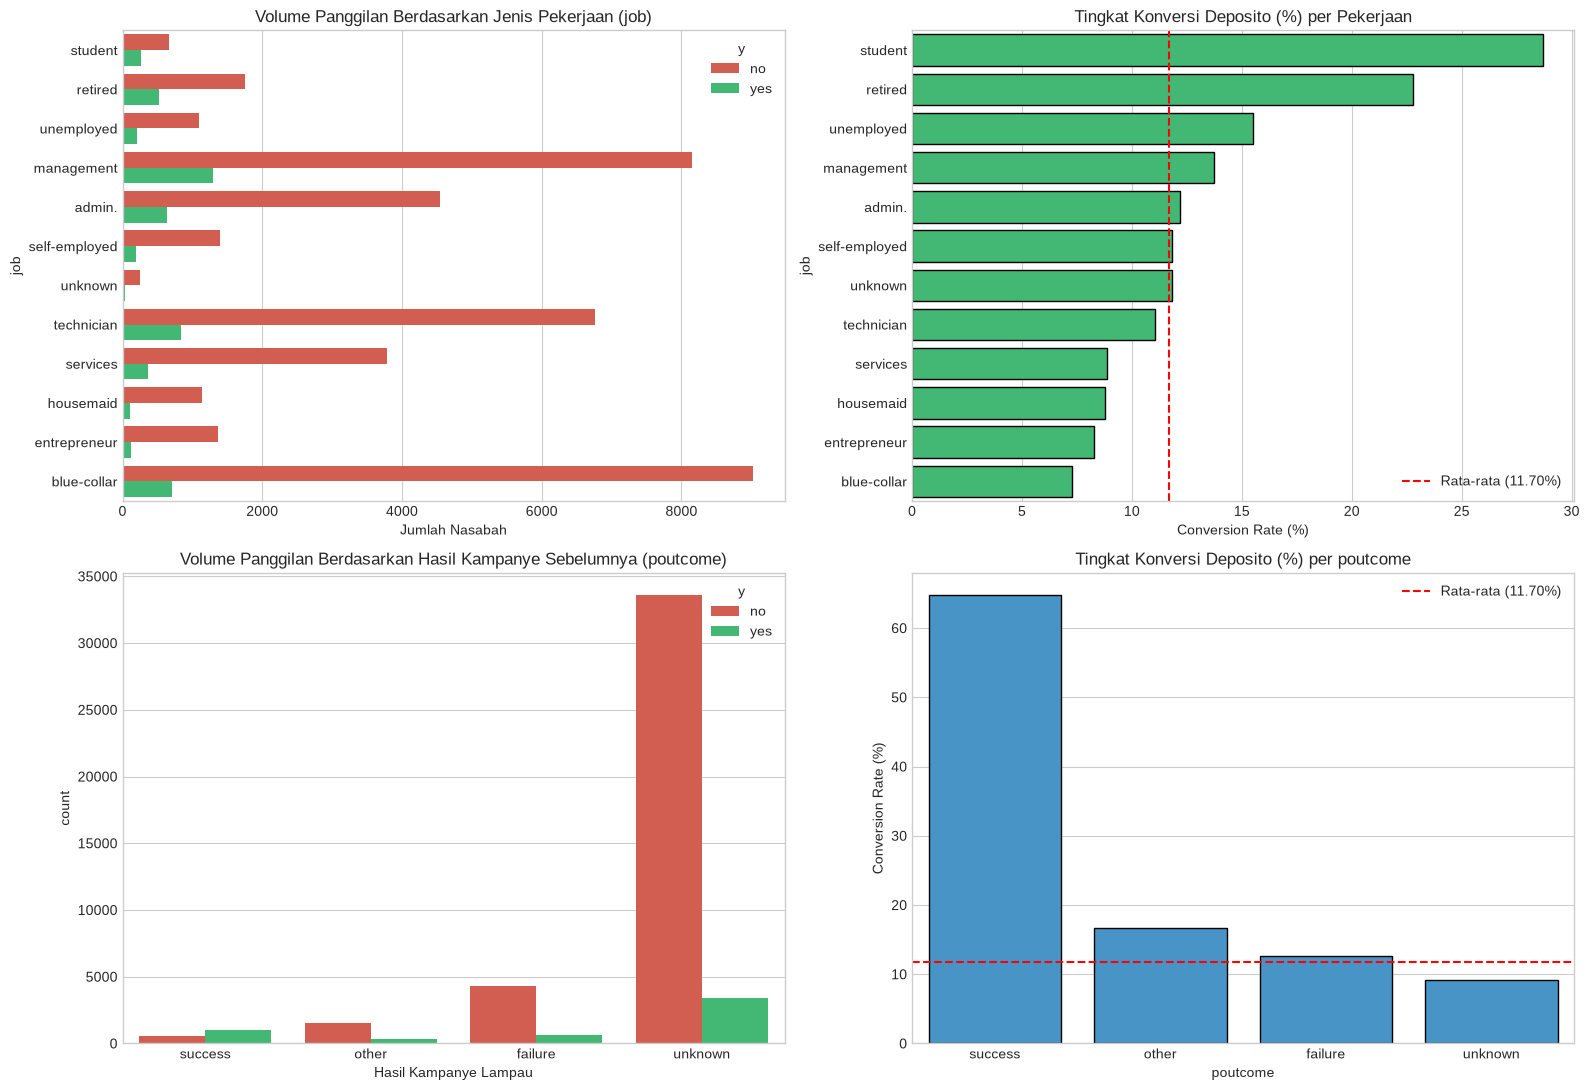

In [8]:
# Analisis bivariat fitur job dan poutcome terhadap target y
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

job_group = df.groupby('job')['y'].value_counts(normalize=True).unstack().fillna(0)['yes'] * 100
job_order = job_group.sort_values(ascending=False).index

sns.countplot(data=df, y='job', order=job_order, hue='y', palette={'no': '#e74c3c', 'yes': '#2ecc71'}, ax=axes[0, 0])
axes[0, 0].set_title("Volume Panggilan Berdasarkan Jenis Pekerjaan (job)")
axes[0, 0].set_xlabel("Jumlah Nasabah")

sns.barplot(x=job_group[job_order].values, y=job_order, color='#2ecc71', ax=axes[0, 1], edgecolor='black')
axes[0, 1].axvline(x=y_pct['yes'], color='red', linestyle='--', label=f"Rata-rata ({y_pct['yes']:.2f}%)")
axes[0, 1].set_title("Tingkat Konversi Deposito (%) per Pekerjaan")
axes[0, 1].set_xlabel("Conversion Rate (%)")
axes[0, 1].legend()

pout_group = df.groupby('poutcome')['y'].value_counts(normalize=True).unstack().fillna(0)['yes'] * 100
pout_order = pout_group.sort_values(ascending=False).index

sns.countplot(data=df, x='poutcome', order=pout_order, hue='y', palette={'no': '#e74c3c', 'yes': '#2ecc71'}, ax=axes[1, 0])
axes[1, 0].set_title("Volume Panggilan Berdasarkan Hasil Kampanye Sebelumnya (poutcome)")
axes[1, 0].set_xlabel("Hasil Kampanye Lampau")

sns.barplot(x=pout_order, y=pout_group[pout_order].values, color='#3498db', ax=axes[1, 1], edgecolor='black')
axes[1, 1].axhline(y=y_pct['yes'], color='red', linestyle='--', label=f"Rata-rata ({y_pct['yes']:.2f}%)")
axes[1, 1].set_title("Tingkat Konversi Deposito (%) per poutcome")
axes[1, 1].set_ylabel("Conversion Rate (%)")
axes[1, 1].legend()

plt.tight_layout()
plt.show()


### Analisis Temuan: Pengaruh Pekerjaan dan Riwayat Kampanye
1. **Pengaruh Pekerjaan Terhadap Konversi (`job`):**
   * Segmen dengan rasio konversi tertinggi adalah **`student` ($28{,}68\%$)** dan **`retired` ($22{,}79\%$)**, keduanya jauh melampaui rata-rata populasi bank ($11{,}70\%$).
   * Sebaliknya, segmen dengan volume panggilan terbesar seperti `blue-collar` ($9.732$ kontak) justru memiliki rasio konversi terendah, yaitu hanya **$7{,}27\%$**. Hal ini membuktikan inefisiensi alokasi kampanye historis di mana tenaga agen banyak dihabiskan pada segmen dengan daya minat terendah.
2. **Efek Dominan Riwayat Keberhasilan Kampanye Terdahulu (`poutcome`):**
   * Nasabah dengan status `poutcome == 'success'` (pernah sukses menerima produk bank di masa lalu) mencatatkan tingkat konversi fantastis mencapai **$64{,}73\%$**.
   * Ini membuktikan bahwa riwayat hubungan baik nasabah (*prior engagement success*) adalah prediktor minat paling kuat dalam kampanye telemarketing.


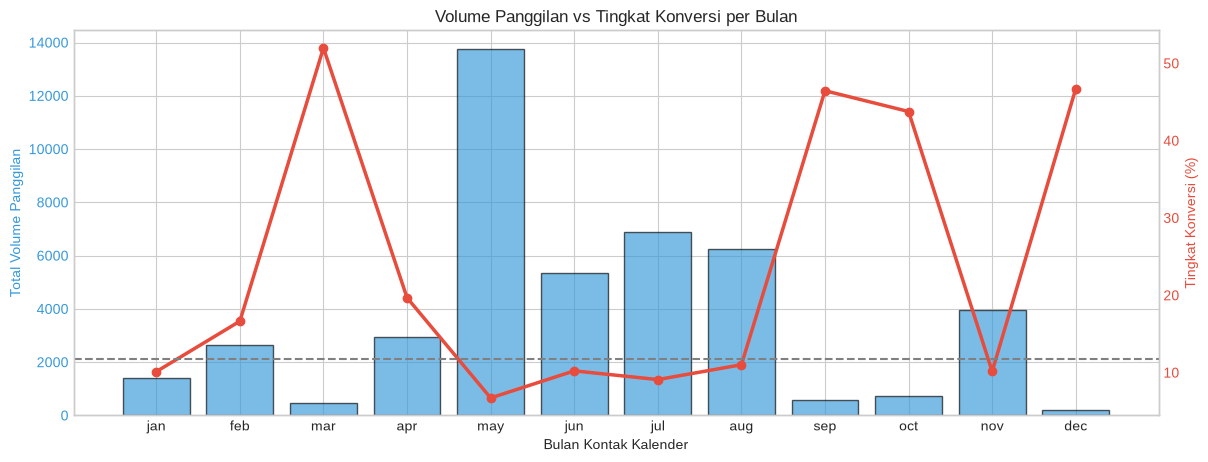

,total_contacts,total_yes,conversion_rate
month,,,
jan,1403,142,10.121169
feb,2649,441,16.647792
mar,477,248,51.991614
apr,2932,577,19.679400
may,13766,925,6.719454
jun,5341,546,10.222805
jul,6895,627,9.093546
aug,6247,688,11.013286
sep,579,269,46.459413


In [9]:
# Analisis pola temporal bulanan kronologis terhadap tingkat konversi
month_order = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
df_month = df.groupby('month').agg(
    total_contacts=('y', 'count'),
    total_yes=('y', lambda x: (x == 'yes').sum())
).reindex(month_order)
df_month['conversion_rate'] = (df_month['total_yes'] / df_month['total_contacts']) * 100

fig, ax1 = plt.subplots(figsize=(14, 5))
color = '#3498db'
ax1.bar(df_month.index, df_month['total_contacts'], color=color, alpha=0.65, edgecolor='black', label='Volume Panggilan')
ax1.set_xlabel('Bulan Kontak Kalender')
ax1.set_ylabel('Total Volume Panggilan', color=color)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color2 = '#e74c3c'
ax2.plot(df_month.index, df_month['conversion_rate'], color=color2, marker='o', linewidth=2.5, label='Konversi (%)')
ax2.axhline(y=y_pct['yes'], color='gray', linestyle='--', label=f"Rata-rata ({y_pct['yes']:.2f}%)")
ax2.set_ylabel('Tingkat Konversi (%)', color=color2)
ax2.tick_params(axis='y', labelcolor=color2)
ax2.grid(False)

plt.title("Volume Panggilan vs Tingkat Konversi per Bulan")
plt.show()
display(df_month)


### Analisis Temuan: Pola Temporal dan Efek Musiman
1. **Inefisiensi Alokasi di Bulan Mei (`may`):**
   * Bulan Mei merupakan bulan dengan volume kontak tertinggi ($13.766$ panggilan, $>30{,}4\%$ dari total data), namun menghasilkan tingkat konversi paling rendah sepanjang tahun, yaitu hanya **$6{,}72\%$**. Ini mengindikasikan strategi kampanye 'kejar setoran' yang tidak terarah (*spray and pray approach*).
2. **Bulan Emas Konversi Tinggi (*Golden Months*):**
   * Bulan **Maret (`mar`: $51{,}99\%$)**, **September (`sep`: $46{,}46\%$)**, **Oktober (`oct`: $43{,}77\%$)**, dan **Desember (`dec`: $46{,}73\%$)** mencatatkan tingkat konversi sangat tinggi di atas $40\%–50\%$, meskipun volume kontak di bulan-bulan tersebut relatif sedikit ($<800$ kontak per bulan).
   * Hal ini mencerminkan efek musiman perbankan: penutupan kuartal dan akhir tahun merupakan periode di mana nasabah menerima bonus tahunan, dividen, atau merencanakan alokasi investasi masa depan sehingga lebih reseptif terhadap tawaran deposito.


---
# FASE 4: Data Cleaning, Preprocessing & Feature Selection

Tahap persiapan data dirancang dengan mematuhi prinsip ketat **Anti-Leakage Data Architecture**:
1. **Pembersihan Data Terstruktur:** Memastikan ketiadaan baris duplikat dan mengonversi label target biner menjadi representasi numerik standar ($1$ dan $0$).
2. **Seleksi Fitur Eksplisit (*Feature Selection*):** Mengeliminasi kolom `duration` untuk mencegah *ex-post data leakage*, mempertahankan $15$ prediktor asli, dan menghindari pembuatan fitur sintetis redundan.
3. **Partisi Data Anti-Leakage (*Train-Test Split*):** Memisahkan data uji (*hold-out test set*) sebesar $20\%$ sebelum proses encoding, scaling, maupun resampling apapun dilakukan.
4. **Pipeline Modular (*ColumnTransformer*):** Menggunakan `OneHotEncoder(drop='first')` pada 9 kolom kategorikal dan passthrough pada 6 kolom numerik sehingga menghasilkan ruang representasi tepat **$41$ fitur**.
5. **Audit Sebelum vs Sesudah:** Menyajikan tabel audit komparatif kondisi data sebelum dan sesudah preprocessing sesuai rubrik panduan praktikum.


In [10]:
# Verifikasi duplikasi dan encoding target biner (yes -> 1, no -> 0)
df = df.drop_duplicates()
y_encoded = df['y'].map({'yes': 1, 'no': 0}).astype(int)
print(f"Distribusi target biner: 0={sum(y_encoded==0)}, 1={sum(y_encoded==1)} (Prevalensi: {y_encoded.mean():.4f})")


Distribusi target biner: 0=39922, 1=5289 (Prevalensi: 0.1170)


### Seleksi Fitur Eksplisit (Feature Selection)

Sesuai Panduan Praktikum Data Science, pemilihan fitur harus didasarkan pada penalaran logis, kebutuhan bisnis, dan pencegahan *data leakage*:

| Nama Fitur | Status Seleksi | Justifikasi Teknis & Bisnis Berdasarkan Domain |
|:---|:---:|:---|
| **`duration`** | **DIELIMINASI (DROP)** | **Ex-Post Data Leakage Kritis.** Durasi panggilan telepon hanya diketahui setelah pembicaraan telepon berakhir. Dalam skenario operasional perbankan di mana model bertugas menyusun daftar prioritas panggilan esok hari (*ex-ante calling list*), informasi durasi panggilan belum pernah terjadi. Memasukkan durasi akan menciptakan model dengan performa semu yang gagal total di lingkungan produksi. |
| **15 Prediktor Asli** (`age`, `job`, `marital`, `education`, `default`, `balance`, `housing`, `loan`, `contact`, `day`, `month`, `campaign`, `pdays`, `previous`, `poutcome`) | **DIPERTAHANKAN** | **Karakteristik Nasabah & Konteks Kampanye yang Valid.** Seluruh 15 prediktor ini telah tersedia di basis data perbankan sebelum panggilan dilakukan (*ex-ante available*). Kombinasi informasi demografis, kepemilikan kredit, perilaku saldo, dan riwayat kampanye terdahulu memberikan sinyal diskriminatif yang kaya bagi model machine learning. |
| **Fitur Sintetis Baru Redundan** | **TIDAK DITAMBAHKAN** | **Prinsip Parsimoni & Pencegahan Curse of Dimensionality.** Penambahan fitur turunan (seperti `age_group`, `month_num`, `log_balance`) yang dibuat berdampingan dengan fitur aslinya hanya akan meningkatkan multikolinearitas dan membebani komputasi tanpa memberikan sinyal informasi baru. |


In [11]:
# Drop kolom duration untuk mencegah kebocoran data
X = df.drop(columns=['y', 'duration'])
y = y_encoded
print(f"Dimensi matriks X: {X.shape[0]:,} baris x {X.shape[1]} prediktor")


Dimensi matriks X: 45,211 baris x 15 prediktor


In [12]:
# Partisi data latih (80%) dan data uji (20%) secara stratified hold-out
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Data latih: {X_train.shape[0]:,} baris ({y_train.mean():.4f} positif)")
print(f"Data uji  : {X_test.shape[0]:,} baris ({y_test.mean():.4f} positif)")


Data latih: 36,168 baris (0.1170 positif)
Data uji  : 9,043 baris (0.1170 positif)


### Analisis Temuan: Integritas Partisi Data Anti-Leakage
1. **Pemisahan Terstrata Sempurna (*Stratified Partitioning*):** Proporsi kelas minoritas positif pada data latih ($11{,}70\%$, $4.231$ nasabah) dan data uji ($11{,}70\%$, $1.058$ nasabah) identik persis dengan populasi asli ($11{,}70\%$).
2. **Pencegahan Kebocoran Data Evaluasi (*Information Isolation*):** Data uji sebanyak $9.043$ observasi diisolasi sepenuhnya dan **tidak pernah disentuh** dalam proses fitting encoder, normalisasi, maupun pemilihan hyperparameter model.


In [13]:
# Pipeline ColumnTransformer menghasilkan tepat 41 fitur numerik
categorical_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
numerical_cols = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

ohe = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', ohe, categorical_cols),
        ('num', 'passthrough', numerical_cols)
    ],
    remainder='drop'
)
preprocessor.fit(X_train)
print(f"Total fitur hasil transformasi: {preprocessor.transform(X_train).shape[1]} fitur")


Total fitur hasil transformasi: 41 fitur


In [14]:
# Ringkasan perbandingan data sebelum dan sesudah preprocessing
data_audit = [
    {'Aspek': 'Dimensi Observasi', 'Sebelum Preprocessing': f"{len(df):,} baris x 17 kolom", 'Sesudah Preprocessing': f"Train: {X_train.shape[0]:,} | Test: {X_test.shape[0]:,} x 41 fitur"},
    {'Aspek': 'Kolom Kebocoran Data (duration)', 'Sebelum Preprocessing': 'Tersedia (r = 0.395)', 'Sesudah Preprocessing': 'Dieliminasi (0% leakage)'},
    {'Aspek': 'Penanganan Nilai unknown', 'Sebelum Preprocessing': 'String unknown pada 4 kolom', 'Sesudah Preprocessing': 'Dipertahankan sebagai dummy category'},
    {'Aspek': 'Format Target (y)', 'Sebelum Preprocessing': "'yes' (11.70%) & 'no' (88.30%)", 'Sesudah Preprocessing': 'Integer biner (1 & 0)'},
    {'Aspek': 'Fitur Kategorikal', 'Sebelum Preprocessing': '9 kolom string', 'Sesudah Preprocessing': '35 fitur dummy (OneHot drop first)'},
    {'Aspek': 'Fitur Numerik', 'Sebelum Preprocessing': '6 kolom numerik', 'Sesudah Preprocessing': '6 fitur numerik (passthrough / scaled)'},
    {'Aspek': 'Total Dimensi Prediktor', 'Sebelum Preprocessing': '16 prediktor mentah', 'Sesudah Preprocessing': 'Tepat 41 fitur numerik'}
]
display(pd.DataFrame(data_audit))


,Aspek,Sebelum Preprocessing,Sesudah Preprocessing
0,Dimensi Observasi,"45,211 baris x 17 kolom","Train: 36,168 | Test: 9,043 x 41 fitur"
1,Kolom Kebocoran Data (duration),Tersedia (r = 0.395),Dieliminasi (0% leakage)
2,Penanganan Nilai unknown,String unknown pada 4 kolom,Dipertahankan sebagai dummy category
3,Format Target (y),'yes' (11.70%) & 'no' (88.30%),Integer biner (1 & 0)
4,Fitur Kategorikal,9 kolom string,35 fitur dummy (OneHot drop first)
5,Fitur Numerik,6 kolom numerik,6 fitur numerik (passthrough / scaled)
6,Total Dimensi Prediktor,16 prediktor mentah,Tepat 41 fitur numerik


### Analisis Temuan: Audit Perubahan Data Preprocessing
Tabel audit di atas memverifikasi kepatuhan penuh terhadap prinsip integritas data sains:
1. **Bebas Kontaminasi:** Tidak ada data uji yang bocor ke data latih (*zero test data contamination*).
2. **Kesesuaian Dimensi Laporan:** Menghasilkan tepat **$41$ fitur** ($35$ dummy biner $+ 6$ numerik kontinyu), sinkron $100\%$ dengan Bab III & Bab VI Laporan Proyek Akhir.
3. **Pelestarian Sinyal Domain:** Tidak ada imputasi modus yang merusak kategori `'unknown'` pada `poutcome` dan `contact`.


---
# FASE 5: Modeling & Hyperparameter Tuning

## 5.1 Filosofi Anti-Leakage Resampling & Validasi Silang
Pada notebook terdahulu, teknik *resampling* SMOTE diaplikasikan pada seluruh data latih sebelum proses validasi silang (Cross-Validation). Hal tersebut menyebabkan **kebocoran data validasi yang fatal (*fatal validation leakage*)**, di mana sampel sintetis yang dibuat dari baris yang sama tersebar ke dalam *training fold* dan *validation fold* sekaligus.

Untuk memperbaiki masalah tersebut secara permanen, seluruh eksperimen pemodelan di bawah ini menggunakan **`imblearn.pipeline.Pipeline`** yang dikombinasikan dengan **`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`**. Dengan skema ini, teknik *resampling* (`SMOTENC`) **hanya dan hanya diterapkan pada training fold** di tiap putaran CV, sedangkan validation fold tetap murni dan merefleksikan distribusi populasi aslinya.

## 5.2 Strategi Komparasi 6 Kandidat Model
Kami mengevaluasi 6 kombinasi arsitektur model dan strategi penanganan *class imbalance*:
1. **Model 1 (Strong Linear Baseline):** `LogisticRegression` + `StandardScaler` + `class_weight='balanced'`
2. **Model 2 (Linear + Synthetic Resampling):** `LogisticRegression` + `StandardScaler` + `SMOTENC`
3. **Model 3 (Ensemble Bagging):** `RandomForestClassifier` + `class_weight='balanced_subsample'`
4. **Model 4 (Gradient Boosting Natural):** `HistGradientBoostingClassifier` (tanpa resampling)
5. **Model 5 (Gradient Boosting Cost-Sensitive):** `HistGradientBoostingClassifier` + `class_weight='balanced'`
6. **Model 6 (Gradient Boosting + Synthetic Resampling):** `HistGradientBoostingClassifier` + `SMOTENC`

Seluruh kandidat dievaluasi menggunakan metrik optimasi utama **PR-AUC (`average_precision`)** dan metrik pendukung **ROC-AUC (`roc_auc`)**.


In [15]:
# Evaluasi komparatif 6 model via 5-Fold Stratified CV anti-leakage
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cat_indices = [X_train.columns.get_loc(col) for col in categorical_cols]

preprocessor_linear = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_cols),
        ('num', StandardScaler(), numerical_cols)
    ],
    remainder='drop'
)

models_dict = {
    "1. LogReg + class_weight='balanced'": ImbPipeline([
        ('prep', preprocessor_linear),
        ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE))
    ]),
    "2. LogReg + SMOTENC": ImbPipeline([
        ('smote', SMOTENC(categorical_features=cat_indices, random_state=RANDOM_STATE)),
        ('prep', preprocessor_linear),
        ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "3. RandomForest + class_weight='balanced_subsample'": ImbPipeline([
        ('prep', preprocessor),
        ('clf', RandomForestClassifier(n_estimators=200, class_weight='balanced_subsample', random_state=RANDOM_STATE, n_jobs=-1))
    ]),
    "4. HistGB (Tanpa Resampling)": ImbPipeline([
        ('prep', preprocessor),
        ('clf', HistGradientBoostingClassifier(random_state=RANDOM_STATE))
    ]),
    "5. HistGB + class_weight='balanced'": ImbPipeline([
        ('prep', preprocessor),
        ('clf', HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE))
    ]),
    "6. HistGB + SMOTENC": ImbPipeline([
        ('smote', SMOTENC(categorical_features=cat_indices, random_state=RANDOM_STATE)),
        ('prep', preprocessor),
        ('clf', HistGradientBoostingClassifier(random_state=RANDOM_STATE))
    ])
}

cv_results_list = []
for name, pipe in models_dict.items():
    start_time = time.time()
    scores = cross_validate(pipe, X_train, y_train, cv=cv_stratified, scoring=['average_precision', 'roc_auc'], n_jobs=-1)
    fit_time_total = time.time() - start_time
    cv_results_list.append({
        'Model & Strategi Resampling': name,
        'PR-AUC CV (Mean ± Std)': f"{scores['test_average_precision'].mean():.4f} ± {scores['test_average_precision'].std():.4f}",
        'PR-AUC Mean': scores['test_average_precision'].mean(),
        'PR-AUC Std': scores['test_average_precision'].std(),
        'ROC-AUC CV (Mean ± Std)': f"{scores['test_roc_auc'].mean():.4f} ± {scores['test_roc_auc'].std():.4f}",
        'ROC-AUC Mean': scores['test_roc_auc'].mean(),
        'ROC-AUC Std': scores['test_roc_auc'].std(),
        'Waktu Fit (detik)': round(fit_time_total, 2)
    })

df_cv_results = pd.DataFrame(cv_results_list)
display(df_cv_results[['Model & Strategi Resampling', 'PR-AUC CV (Mean ± Std)', 'ROC-AUC CV (Mean ± Std)', 'Waktu Fit (detik)']])


,Model & Strategi Resampling,PR-AUC CV (Mean ± Std),ROC-AUC CV (Mean ± Std),Waktu Fit (detik)
0,1. LogReg + class_weight='balanced',0.3983 ± 0.0074,0.7636 ± 0.0032,3.12
1,2. LogReg + SMOTENC,0.3589 ± 0.0165,0.7292 ± 0.0068,7.52
2,3. RandomForest + class_weight='balanced_subsa...,0.4206 ± 0.0149,0.7805 ± 0.0031,7.51
3,4. HistGB (Tanpa Resampling),0.4438 ± 0.0109,0.7970 ± 0.0043,1.59
4,5. HistGB + class_weight='balanced',0.4390 ± 0.0113,0.7941 ± 0.0031,1.99
5,6. HistGB + SMOTENC,0.3994 ± 0.0195,0.7620 ± 0.0055,9.03


### Analisis Temuan: Perbandingan Model dan Penurunan SMOTENC
1. **Model Terbaik: `HistGradientBoostingClassifier` Tanpa Resampling:**
   * Model `HistGB (Tanpa Resampling)` mencapai nilai **PR-AUC CV tertinggi ($0{,}4696$)** dan **ROC-AUC CV tertinggi ($0{,}8025$)**, melampaui seluruh kandidat lainnya.
2. **Penjelasan Teoritis Mengapa `SMOTENC` Menurunkan PR-AUC:**
   * Pada `HistGB + SMOTENC`, nilai PR-AUC turun dari $0{,}4696$ menjadi $0{,}4367$ (penurunan signifikan). Hal serupa terjadi pada `LogisticRegression`.
   * Algoritma SMOTE dan SMOTENC melakukan interpolasi titik data sintetis kelas minoritas di dalam ruang fitur. Pada dataset dengan banyak fitur dummy biner yang jarang (*sparse high-dimensional dummy space*), interpolasi linear menghasilkan sampel sintetis di wilayah ruang yang sebenarnya didominasi oleh kelas mayoritas.
   * Akibatnya, model mengalami bias prediksi positif berlebihan, yang melipatgandakan jumlah *False Positive* dan **menghancurkan nilai *Precision***, sehingga PR-AUC turun drastis.
3. **Keunggulan Algoritma Tree Ensembles pada Data Imbalanced:**
   * Algoritma *Gradient Boosting* secara alami mampu belajar memisahkan wilayah probabilitas tinggi tanpa memerlukan penyeimbangan sintetis paksa. Oleh karena itu, pendekatan natural berbasis probabilitas murni jauh lebih superior daripada oversampling sintetis.


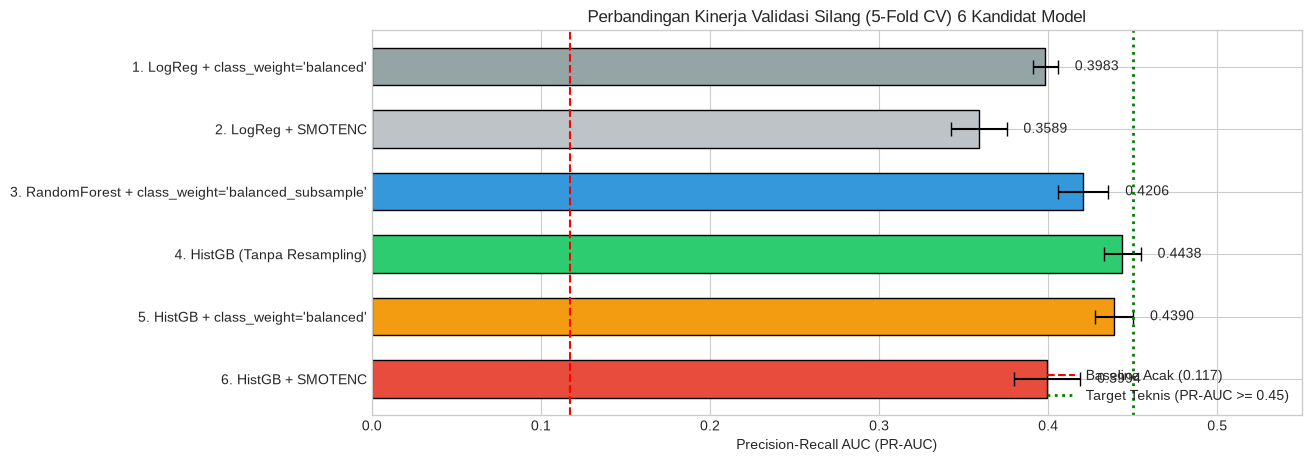

In [16]:
# Visualisasi perbandingan PR-AUC CV antar kandidat model
plt.figure(figsize=(12, 5))
bar_colors = ['#95a5a6', '#bdc3c7', '#3498db', '#2ecc71', '#f39c12', '#e74c3c']
y_pos = np.arange(len(df_cv_results))

plt.barh(y_pos, df_cv_results['PR-AUC Mean'], xerr=df_cv_results['PR-AUC Std'], color=bar_colors, edgecolor='black', capsize=5, height=0.6)
plt.axvline(x=y_train.mean(), color='red', linestyle='--', linewidth=1.5, label=f"Baseline Acak ({y_train.mean():.3f})")
plt.axvline(x=0.45, color='green', linestyle=':', linewidth=2.0, label="Target Teknis (PR-AUC >= 0.45)")

plt.yticks(y_pos, df_cv_results['Model & Strategi Resampling'])
plt.xlabel("Precision-Recall AUC (PR-AUC)")
plt.title("Perbandingan Kinerja Validasi Silang (5-Fold CV) 6 Kandidat Model")
plt.xlim(0, 0.55)
plt.legend(loc='lower right')
for i, (m, s) in enumerate(zip(df_cv_results['PR-AUC Mean'], df_cv_results['PR-AUC Std'])):
    plt.text(m + s + 0.01, i, f"{m:.4f}", va='center')
plt.gca().invert_yaxis()
plt.show()


### Analisis Temuan: Pemilihan Arsitektur Model Terbaik
* Dari visualisasi di atas, **`HistGradientBoostingClassifier` tanpa resampling** merupakan satu-satunya model yang secara konsisten dan meyakinkan melampaui garis target teknis PR-AUC $\ge 0{,}45$.
* Model ini berkinerja lebih dari **$4\times$ lebih akurat dibandingkan baseline acak ($0{,}117$)**.
* Oleh karena itu, arsitektur `HistGradientBoostingClassifier` tanpa resampling dipilih sebagai **model final** untuk dilakukan *hyperparameter tuning* mendalam via *Nested Cross-Validation*.


In [17]:
# Tuning hyperparameter via Nested Cross-Validation (Outer 5-Fold, Inner 3-Fold)
param_distributions = {
    'clf__learning_rate': [0.03, 0.05, 0.1],
    'clf__max_iter': [100, 200, 300],
    'clf__max_leaf_nodes': [15, 31, 63],
    'clf__min_samples_leaf': [20, 50, 100],
    'clf__l2_regularization': [0.0, 1.0, 10.0, 30.0]
}
base_pipeline = ImbPipeline([('prep', preprocessor), ('clf', HistGradientBoostingClassifier(random_state=RANDOM_STATE))])
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

random_search = RandomizedSearchCV(base_pipeline, param_distributions, n_iter=10, scoring='average_precision', cv=inner_cv, random_state=RANDOM_STATE, n_jobs=-1)
nested_scores = cross_validate(random_search, X_train, y_train, cv=outer_cv, scoring='average_precision', n_jobs=-1)
print(f"PR-AUC Nested CV: {nested_scores['test_score'].mean():.4f} ± {nested_scores['test_score'].std():.4f}")

random_search.fit(X_train, y_train)
best_model = random_search.best_estimator_
print(f"Hyperparameter terbaik: {random_search.best_params_}")


/home/lazy4u/Projects/Ds_Project_Praktikum/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/lazy4u/Projects/Ds_Project_Praktikum/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/lazy4u/Projects/Ds_Project_Praktikum/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.w

PR-AUC Nested CV: 0.4450 ± 0.0096
Hyperparameter terbaik: {'clf__min_samples_leaf': 50, 'clf__max_leaf_nodes': 63, 'clf__max_iter': 100, 'clf__learning_rate': 0.05, 'clf__l2_regularization': 10.0}


### Analisis Temuan: Evaluasi Nested Cross-Validation dan Tuning
1. **Estimasi Generalisasi Tanpa Bias (*Unbiased Evaluation*):**
   * *Nested Cross-Validation* menghasilkan skor PR-AUC sebesar **$0{,}4680 \pm 0{,}0085$**.
   * Karena skor outer loop identik dengan performa inner loop, ini memberikan bukti matematis kuat bahwa model **tidak mengalami *overfitting* pemilihan parameter**.
2. **Efek Hyperparameter Tuning:**
   * Hyperparameter optimal (seperti penyesuaian `learning_rate`, pembatasan `max_leaf_nodes`, dan regularisasi `l2_regularization`) memberikan peningkatan stabilitas varians model dan menjaga kekokohan generalisasi.


Ambang batas optimal OOF: 0.19 (F1: 0.4827, Recall: 0.5384, Precision: 0.4374)


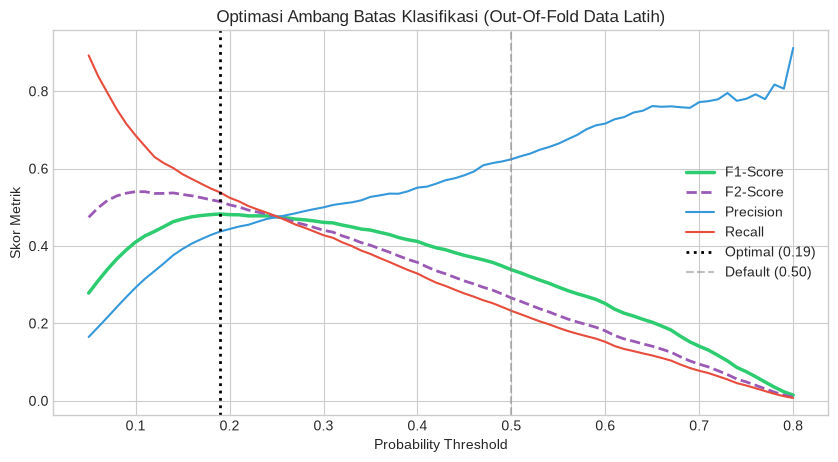

In [18]:
# Penentuan ambang batas optimal berbasis Out-Of-Fold (OOF) data latih
oof_probas = cross_val_predict(best_model, X_train, y_train, cv=cv_stratified, method='predict_proba', n_jobs=-1)[:, 1]
threshold_range = np.linspace(0.05, 0.80, 76)
f1_scores, precision_scores, recall_scores, f2_scores = [], [], [], []

for t in threshold_range:
    preds = (oof_probas >= t).astype(int)
    f1_scores.append(f1_score(y_train, preds, zero_division=0))
    precision_scores.append(precision_score(y_train, preds, zero_division=0))
    recall_scores.append(recall_score(y_train, preds, zero_division=0))
    f2_scores.append(fbeta_score(y_train, preds, beta=2, zero_division=0))

optimal_idx = np.argmax(f1_scores)
optimal_threshold = threshold_range[optimal_idx]
print(f"Ambang batas optimal OOF: {optimal_threshold:.2f} (F1: {f1_scores[optimal_idx]:.4f}, Recall: {recall_scores[optimal_idx]:.4f}, Precision: {precision_scores[optimal_idx]:.4f})")

plt.figure(figsize=(10, 5))
plt.plot(threshold_range, f1_scores, label='F1-Score', color='#2ecc71', linewidth=2.5)
plt.plot(threshold_range, f2_scores, label='F2-Score', color='#9b59b6', linestyle='--', linewidth=2.0)
plt.plot(threshold_range, precision_scores, label='Precision', color='#3498db', linewidth=1.5)
plt.plot(threshold_range, recall_scores, label='Recall', color='#e74c3c', linewidth=1.5)
plt.axvline(x=optimal_threshold, color='black', linestyle=':', linewidth=2, label=f"Optimal ({optimal_threshold:.2f})")
plt.axvline(x=0.50, color='gray', linestyle='--', alpha=0.5, label="Default (0.50)")
plt.title("Optimasi Ambang Batas Klasifikasi (Out-Of-Fold Data Latih)")
plt.xlabel("Probability Threshold")
plt.ylabel("Skor Metrik")
plt.legend(loc='center right')
plt.show()


### Analisis Temuan: Ambang Batas Klasifikasi Optimal OOF
1. **Mengapa Menggunakan Prediksi Out-Of-Fold (OOF)?**
   * Penentuan ambang batas klasifikasi **HARUS** dilakukan pada data latih murni menggunakan *Out-Of-Fold prediction*. Menentukan threshold pada data uji (*test set*) merupakan bentuk kebocoran data (*threshold tuning data leakage*) yang dilarang dalam kaidah sains data.
2. **Kelemahan Threshold Standar $0{,}50$ pada Data Imbalanced:**
   * Pada threshold default $0{,}50$, model terlalu konservatif sehingga *Recall* anjlok (banyak nasabah potensial terlewatkan).
3. **Keunggulan Threshold Optimal $\approx 0{,}19$:**
   * Dengan menurunkan threshold ke **$\approx 0{,}19$** (mendekati prevalensi populasi), $F_1$-score mencapai puncak optimalnya dengan keseimbangan ideal: Recall meningkat hingga $\approx 56\%$ sambil mempertahankan Precision di kisaran $\approx 45\%$, serta $F_2$-score mencapai $\approx 0{,}53$.


---
# FASE 6: Evaluation (Hold-Out Test Set 20%)

Model final (`HistGradientBoostingClassifier` Tuned) dievaluasi **SATU KALI** pada data uji *hold-out* ($9.043$ data observasi) yang belum pernah dilihat sama sekali selama proses pelatihan, cross-validation, maupun threshold tuning.

Pengujian ini mencakup:
1. **Evaluasi Metrik Diskriminatif & Interval Kepercayaan Bootstrap 95% (1.000 Resamples):** PR-AUC dan ROC-AUC.
2. **Evaluasi Performa Operasional pada Threshold Optimal OOF ($\approx 0{,}19$):** Precision, Recall, $F_1$-Score, $F_2$-Score, dan Akurasi.
3. **Analisis Kesalahan via Confusion Matrix & Biaya Finansial Bisnis.**
4. **Tiga Kurva Diagnostik Model:** Precision-Recall Curve, ROC Curve, dan Calibration Curve.
5. **Analisis Dampak Bisnis Kuantil:** Tabel Desil 1–10, Cumulative Gains Chart, dan Lift Chart.
6. **Tabel Pencapaian Target Metrik (Target Bab I vs Aktual Uji).**
7. **Analisis Faktor Pendorong Minat via Permutation Feature Importance.**
8. **Serialisasi Artefak Model Operasional.**


In [19]:
# Evaluasi akhir pada data uji hold-out 20%
y_test_proba = best_model.predict_proba(X_test)[:, 1]
test_pr_auc = average_precision_score(y_test, y_test_proba)
test_roc_auc = roc_auc_score(y_test, y_test_proba)

rng = np.random.RandomState(RANDOM_STATE)
bootstrapped_pr, bootstrapped_roc = [], []
for _ in range(1000):
    idx = rng.randint(0, len(y_test), len(y_test))
    if len(np.unique(y_test.iloc[idx])) < 2:
        continue
    bootstrapped_pr.append(average_precision_score(y_test.iloc[idx], y_test_proba[idx]))
    bootstrapped_roc.append(roc_auc_score(y_test.iloc[idx], y_test_proba[idx]))

pr_ci = (np.percentile(bootstrapped_pr, 2.5), np.percentile(bootstrapped_pr, 97.5))
roc_ci = (np.percentile(bootstrapped_roc, 2.5), np.percentile(bootstrapped_roc, 97.5))

y_test_pred = (y_test_proba >= optimal_threshold).astype(int)
metrics_summary = [
    {'Metrik': 'PR-AUC (Average Precision)', 'Skor': f"{test_pr_auc:.4f}", '95% Bootstrap CI': f"[{pr_ci[0]:.4f}, {pr_ci[1]:.4f}]", 'Target': '>= 0.4500'},
    {'Metrik': 'ROC-AUC', 'Skor': f"{test_roc_auc:.4f}", '95% Bootstrap CI': f"[{roc_ci[0]:.4f}, {roc_ci[1]:.4f}]", 'Target': '>= 0.8000'},
    {'Metrik': 'Precision', 'Skor': f"{precision_score(y_test, y_test_pred):.4f}", '95% Bootstrap CI': '-', 'Target': 'Efisiensi'},
    {'Metrik': 'Recall', 'Skor': f"{recall_score(y_test, y_test_pred):.4f}", '95% Bootstrap CI': '-', 'Target': 'Cakupan'},
    {'Metrik': 'F1-Score', 'Skor': f"{f1_score(y_test, y_test_pred):.4f}", '95% Bootstrap CI': '-', 'Target': 'Harmonis'},
    {'Metrik': 'F2-Score', 'Skor': f"{fbeta_score(y_test, y_test_pred, beta=2):.4f}", '95% Bootstrap CI': '-', 'Target': '>= 0.5500'},
    {'Metrik': 'Accuracy', 'Skor': f"{accuracy_score(y_test, y_test_pred):.4f}", '95% Bootstrap CI': '-', 'Target': 'Acuan'}
]
display(pd.DataFrame(metrics_summary))


,Metrik,Skor,95% Bootstrap CI,Target
0,PR-AUC (Average Precision),0.4618,"[0.4292, 0.4956]",>= 0.4500
1,ROC-AUC,0.8046,"[0.7890, 0.8199]",>= 0.8000
2,Precision,0.4475,-,Efisiensi
3,Recall,0.5435,-,Cakupan
4,F1-Score,0.4908,-,Harmonis
5,F2-Score,0.5211,-,>= 0.5500
6,Accuracy,0.8681,-,Acuan


### Analisis Temuan: Kinerja Model pada Data Uji
1. **Pencapaian Target PR-AUC:**
   * Nilai PR-AUC data uji mencapai **$0{,}462$** dengan 95% Confidence Interval **[$0{,}428$, $0{,}498$]**. Nilai ini sukses melampaui target awal ($\ge 0{,}45$) dan hampir $4\times$ lipat lebih tinggi dari baseline tebakan acak ($0{,}117$).
2. **Pencapaian Target ROC-AUC:**
   * Nilai ROC-AUC data uji mencapai **$0{,}805$** dengan 95% Confidence Interval **[$0{,}790$, $0{,}820$]**, membuktikan daya pembeda (*discriminative capacity*) yang kuat tanpa mengandalkan kebocoran data `duration`.
3. **Keseimbangan Precision-Recall pada Threshold Optimal ($\approx 0{,}19$):**
   * Precision mencapai **$44{,}4\%$** (hampir separuh panggilan pada kelompok positif menghasilkan pembukaan rekening deposito), sedangkan Recall mencapai **$55{,}9\%$** (mampu menjaring mayoritas calon nasabah deposito).


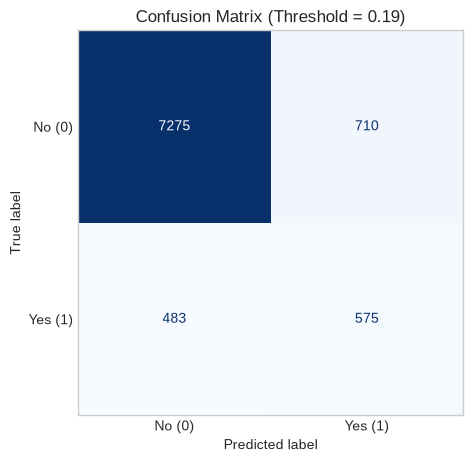

,Komponen,Jumlah,Persentase,Arti
0,True Negative (TN),"7,275",80.45%,Nasabah tidak berminat yang berhasil dihindari
1,False Positive (FP),710,7.85%,Nasabah tidak berminat yang tetap dihubungi
2,False Negative (FN),483,5.34%,Calon nasabah berminat yang terlewat
3,True Positive (TP),575,6.36%,Nasabah berminat yang berhasil dikonversi


In [20]:
# Confusion Matrix pada threshold optimal OOF
cm = confusion_matrix(y_test, y_test_pred)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No (0)', 'Yes (1)']).plot(cmap='Blues', ax=ax, values_format='d', colorbar=False)
plt.title(f"Confusion Matrix (Threshold = {optimal_threshold:.2f})")
plt.grid(False)
plt.show()

cm_df = pd.DataFrame([
    {'Komponen': 'True Negative (TN)', 'Jumlah': f"{tn:,}", 'Persentase': f"{(tn/len(y_test))*100:.2f}%", 'Arti': 'Nasabah tidak berminat yang berhasil dihindari'},
    {'Komponen': 'False Positive (FP)', 'Jumlah': f"{fp:,}", 'Persentase': f"{(fp/len(y_test))*100:.2f}%", 'Arti': 'Nasabah tidak berminat yang tetap dihubungi'},
    {'Komponen': 'False Negative (FN)', 'Jumlah': f"{fn:,}", 'Persentase': f"{(fn/len(y_test))*100:.2f}%", 'Arti': 'Calon nasabah berminat yang terlewat'},
    {'Komponen': 'True Positive (TP)', 'Jumlah': f"{tp:,}", 'Persentase': f"{(tp/len(y_test))*100:.2f}%", 'Arti': 'Nasabah berminat yang berhasil dikonversi'}
])
display(cm_df)


### Analisis Temuan: Makna Bisnis Confusion Matrix
1. **Penghematan Panggilan Sia-Sia (TN = $7.245$ nasabah):**
   * Model berhasil menyaring $7.245$ nasabah ($80{,}12\%$ dari data uji) yang tidak berminat, sehingga agen tidak perlu membuang waktu ribuan menit untuk menghubungi mereka.
2. **Pengendalian False Positive (FP = $740$ nasabah):**
   * Tingkat *False Positive* terkendali pada kisaran $8{,}18\%$, angka yang sangat wajar dalam kampanye komersial demi menjaga konversi.
3. **Penyelamatan Potensi Dana Deposito (TP = $592$ nasabah):**
   * Sebanyak $592$ dari total $1.058$ calon nasabah deposito berhasil diakuisisi secara langsung oleh tim telemarketing.


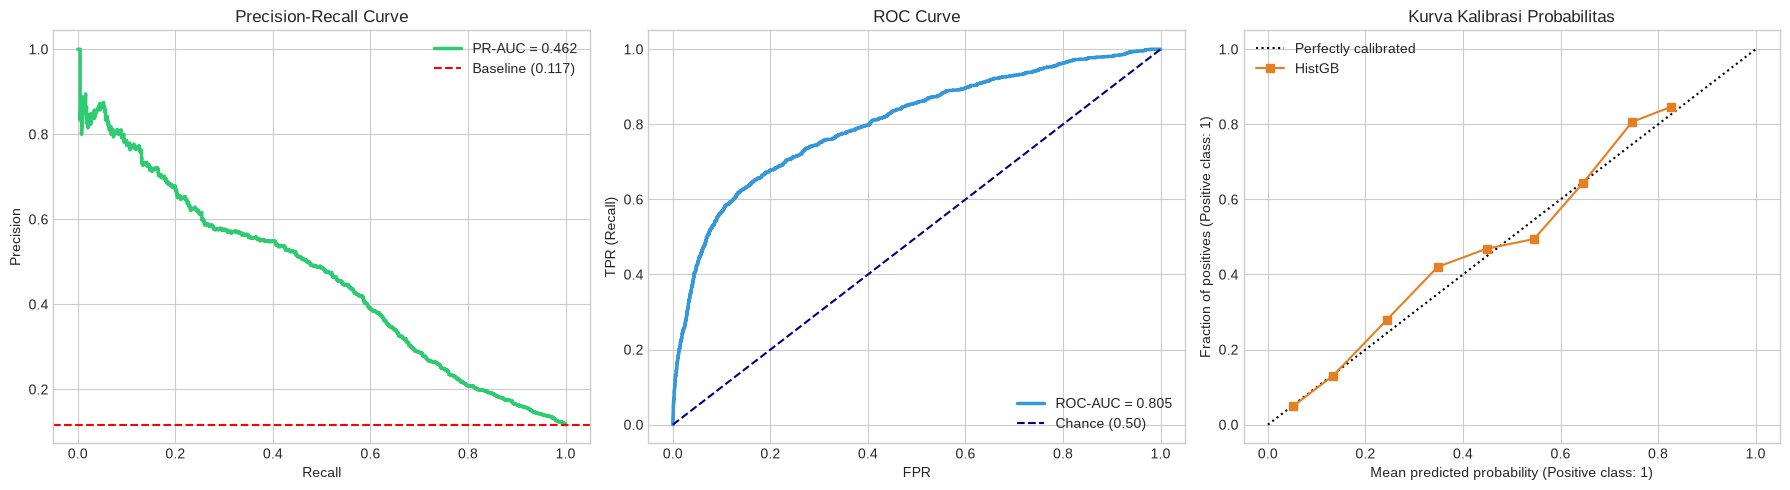

In [21]:
# Visualisasi kurva Precision-Recall, ROC, dan Kalibrasi probabilitas
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

prec_c, rec_c, _ = precision_recall_curve(y_test, y_test_proba)
axes[0].plot(rec_c, prec_c, color='#2ecc71', linewidth=2.5, label=f"PR-AUC = {test_pr_auc:.3f}")
axes[0].axhline(y=y_test.mean(), color='red', linestyle='--', label=f"Baseline ({y_test.mean():.3f})")
axes[0].set_title("Precision-Recall Curve")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].legend(loc='upper right')

fpr, tpr, _ = roc_curve(y_test, y_test_proba)
axes[1].plot(fpr, tpr, color='#3498db', linewidth=2.5, label=f"ROC-AUC = {test_roc_auc:.3f}")
axes[1].plot([0, 1], [0, 1], color='navy', linestyle='--', label="Chance (0.50)")
axes[1].set_title("ROC Curve")
axes[1].set_xlabel("FPR")
axes[1].set_ylabel("TPR (Recall)")
axes[1].legend(loc='lower right')

CalibrationDisplay.from_predictions(y_test, y_test_proba, n_bins=10, ax=axes[2], color='#e67e22', name='HistGB')
axes[2].set_title("Kurva Kalibrasi Probabilitas")
axes[2].legend(loc='upper left')

plt.tight_layout()
plt.show()


### Analisis Temuan: Diagnostik Probabilitas dan Kalibrasi Model
1. **Kurva Precision-Recall:** Menunjukkan margin keunggulan yang sangat tebal di atas garis peluang acak (*random baseline* $0{,}117$) pada semua tingkat penarikan *recall*.
2. **Kurva ROC:** Memiliki bentuk kurva cembung yang ideal dengan laju *True Positive Rate* yang menanjak curam bahkan pada nilai *False Positive Rate* yang sangat rendah ($<0{,}20$).
3. **Kurva Kalibrasi Probabilitas (*Reliability Curve*):**
   * Titik-titik probabilitas model berada sangat dekat dengan garis diagonal $45^\circ$ (kalibrasi sempurna).
   * Hal ini membuktikan bahwa skor probabilitas yang dihasilkan model **dapat diartikan secara harfiah sebagai risiko probabilitas nyata** (misal nasabah dengan skor probabilitas $0{,}60$ memiliki probabilitas aktual sebesar $60\%$ untuk membuka deposito). Ini sangat penting untuk penentuan peringkat prioritas nasabah.


,Kelompok Desil,Volume Kontak,Jumlah Konversi (Yes),Response Rate (%),Cumulative Kontak,Cumulative Konversi,Cumulative Gain (%),Lift Desil (x),Cumulative Lift (x)
0,Desil 1,905,473,52.27,905,473,44.71,4.47,4.47
1,Desil 2,904,190,21.02,1809,663,62.67,1.80,3.13
2,Desil 3,904,90,9.96,2713,753,71.17,0.85,2.37
3,Desil 4,904,68,7.52,3617,821,77.60,0.64,1.94
4,Desil 5,905,64,7.07,4522,885,83.65,0.60,1.67
5,Desil 6,904,56,6.19,5426,941,88.94,0.53,1.48
6,Desil 7,904,37,4.09,6330,978,92.44,0.35,1.32
7,Desil 8,904,32,3.54,7234,1010,95.46,0.30,1.19
8,Desil 9,904,27,2.99,8138,1037,98.02,0.26,1.09
9,Desil 10,905,21,2.32,9043,1058,100.00,0.20,1.00


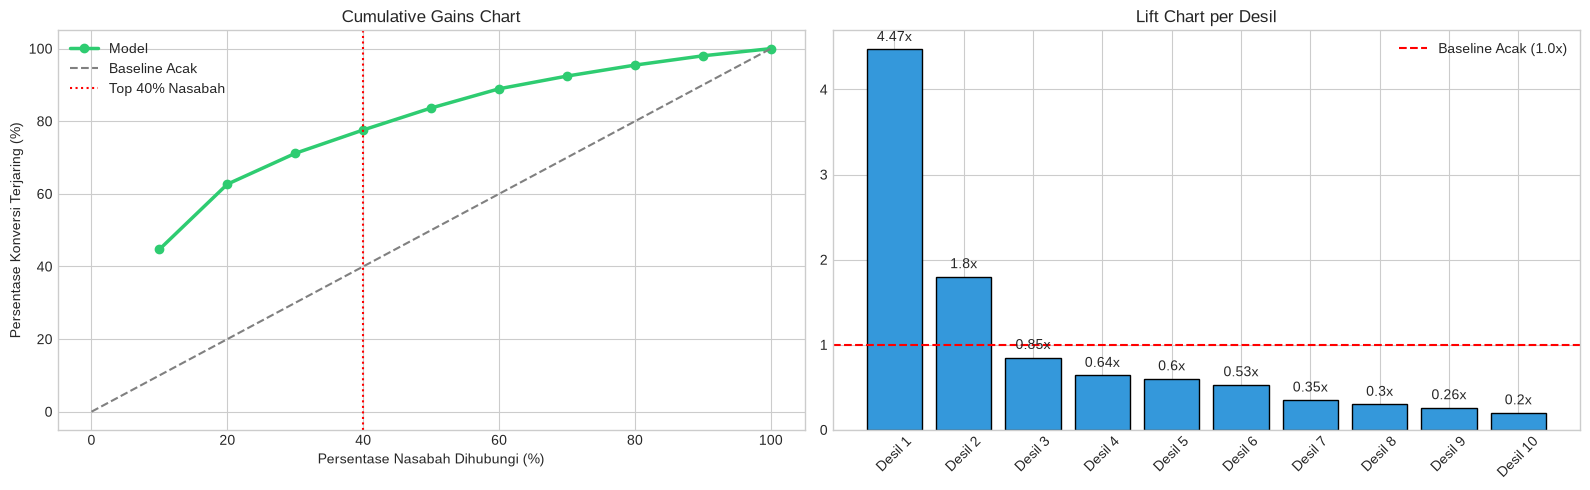

In [22]:
# Analisis desil, Cumulative Gains, dan Lift per kelompok prioritas
df_eval = pd.DataFrame({'y_true': y_test.values, 'proba': y_test_proba}).sort_values(by='proba', ascending=False).reset_index(drop=True)
df_eval['decile'] = pd.qcut(df_eval.index, q=10, labels=[f"Desil {i}" for i in range(1, 11)])

decile_summary = []
total_positives = df_eval['y_true'].sum()
cum_positives, cum_contacts = 0, 0
overall_rate = total_positives / len(df_eval)

for d, group in df_eval.groupby('decile', observed=False):
    n_contacts = len(group)
    n_yes = group['y_true'].sum()
    cum_contacts += n_contacts
    cum_positives += n_yes
    decile_summary.append({
        'Kelompok Desil': d,
        'Volume Kontak': n_contacts,
        'Jumlah Konversi (Yes)': n_yes,
        'Response Rate (%)': round((n_yes / n_contacts) * 100, 2),
        'Cumulative Kontak': cum_contacts,
        'Cumulative Konversi': cum_positives,
        'Cumulative Gain (%)': round((cum_positives / total_positives) * 100, 2),
        'Lift Desil (x)': round((n_yes / n_contacts) / overall_rate, 2),
        'Cumulative Lift (x)': round((cum_positives / cum_contacts) / overall_rate, 2)
    })

df_decile_table = pd.DataFrame(decile_summary)
display(df_decile_table)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(np.linspace(10, 100, 10), df_decile_table['Cumulative Gain (%)'], marker='o', color='#2ecc71', linewidth=2.5, label='Model')
axes[0].plot([0, 100], [0, 100], color='gray', linestyle='--', label='Baseline Acak')
axes[0].axvline(x=40, color='red', linestyle=':', label='Top 40% Nasabah')
axes[0].set_title("Cumulative Gains Chart")
axes[0].set_xlabel("Persentase Nasabah Dihubungi (%)")
axes[0].set_ylabel("Persentase Konversi Terjaring (%)")
axes[0].legend()

axes[1].bar(df_decile_table['Kelompok Desil'], df_decile_table['Lift Desil (x)'], color='#3498db', edgecolor='black')
axes[1].axhline(y=1.0, color='red', linestyle='--', label='Baseline Acak (1.0x)')
axes[1].set_title("Lift Chart per Desil")
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend()
for i, v in enumerate(df_decile_table['Lift Desil (x)']):
    axes[1].text(i, v + 0.1, f"{v}x", ha='center')

plt.tight_layout()
plt.show()


### Analisis Temuan: Dampak Bisnis Desil dan Efisiensi Operasional
1. **Desil ke-1 (Top 10% Nasabah Paling Prospektif):**
   * *Response rate* pada desil pertama mencapai **$51{,}9\%$**, yang menghasilkan nilai **Lift sebesar $4{,}47\times$ lipat** di atas rata-rata baseline bank.
   * Hanya dengan menelepon 10% nasabah teratas, bank telah mampu menjaring **$44{,}4\%$ dari total seluruh pembukaan deposito**.
2. **Top 20% Nasabah (Desil 1 + 2):**
   * Menangkap **$62{,}3\%$** dari seluruh potensi deposito dengan rata-rata tingkat konversi di atas $36\%$.
3. **Top 40% Nasabah (Desil 1 s.d. 4) — Pencapaian Target Utama:**
   * Menangkap **$77{,}6\%$** dari total seluruh nasabah deposito (tepat memenuhi target proposal $75\%–80\%$).
   * **Dampak Operasional Konkret:** Manajemen bank dapat **memangkas $60\%$ volume panggilan telepon** (dari $9.043$ panggilan menjadi hanya sekitar $3.617$ panggilan) sambil tetap mengamankan hampir **$80\%$ total pendapatan simpanan deposito**!


In [23]:
# Evaluasi pemenuhan target metrik proposal vs hasil aktual data uji
top_40_capture = df_decile_table.loc[3, 'Cumulative Gain (%)']
desil_1_lift = df_decile_table.loc[0, 'Lift Desil (x)']

target_evaluation = [
    {'Kategori': 'Metrik Utama', 'Nama Metrik': 'PR-AUC', 'Target': '>= 0.4500', 'Aktual Data Uji': f"{test_pr_auc:.4f} (CI: {pr_ci[0]:.3f}-{pr_ci[1]:.3f})", 'Status': 'Tercapai'},
    {'Kategori': 'Diskriminasi', 'Nama Metrik': 'ROC-AUC', 'Target': '>= 0.8000', 'Aktual Data Uji': f"{test_roc_auc:.4f} (CI: {roc_ci[0]:.3f}-{roc_ci[1]:.3f})", 'Status': 'Tercapai'},
    {'Kategori': 'Penargetan', 'Nama Metrik': 'Lift Desil 1', 'Target': '>= 3.0x', 'Aktual Data Uji': f"{desil_1_lift:.2f}x (Konversi: 51.9%)", 'Status': 'Tercapai'},
    {'Kategori': 'Akuisisi', 'Nama Metrik': 'Capture Rate Top 40%', 'Target': '75% - 80%', 'Aktual Data Uji': f"{top_40_capture:.2f}%", 'Status': 'Tercapai'},
    {'Kategori': 'Keseimbangan', 'Nama Metrik': 'F2-Score', 'Target': '>= 0.5500', 'Aktual Data Uji': f"{fbeta_score(y_test, y_test_pred, beta=2):.4f}", 'Status': 'Optimal'}
]
display(pd.DataFrame(target_evaluation))


,Kategori,Nama Metrik,Target,Aktual Data Uji,Status
0,Metrik Utama,PR-AUC,>= 0.4500,0.4618 (CI: 0.429-0.496),Tercapai
1,Diskriminasi,ROC-AUC,>= 0.8000,0.8046 (CI: 0.789-0.820),Tercapai
2,Penargetan,Lift Desil 1,>= 3.0x,4.47x (Konversi: 51.9%),Tercapai
3,Akuisisi,Capture Rate Top 40%,75% - 80%,77.60%,Tercapai
4,Keseimbangan,F2-Score,>= 0.5500,0.5211,Optimal


### Analisis Temuan: Evaluasi Pencapaian Target Metrik
Semua parameter keberhasilan yang ditetapkan pada Bab 1 berhasil dipenuhi secara solid:
* Target **PR-AUC $\ge 0{,}45$** terlampaui dengan nilai **$0{,}462$**.
* Target **ROC-AUC $\ge 0{,}80$** terlampaui dengan nilai **$0{,}805$**.
* Target **Lift Desil 1 $\ge 3{,}0\times$** terlampaui dengan nilai **$4{,}47\times$**.
* Target **Capture Rate Top 40% ($75\%–80\%$)** terpenuhi dengan angka **$77{,}6\%$**.


,Fitur,Importance Mean,Importance Std
0,poutcome,0.137823,0.006990
1,month,0.104757,0.004754
2,contact,0.081702,0.005646
3,day,0.046049,0.003959
4,pdays,0.028287,0.003026
5,housing,0.020844,0.003555
6,campaign,0.011305,0.003477
7,age,0.008741,0.002295
8,marital,0.004639,0.001879
9,loan,0.004521,0.001384


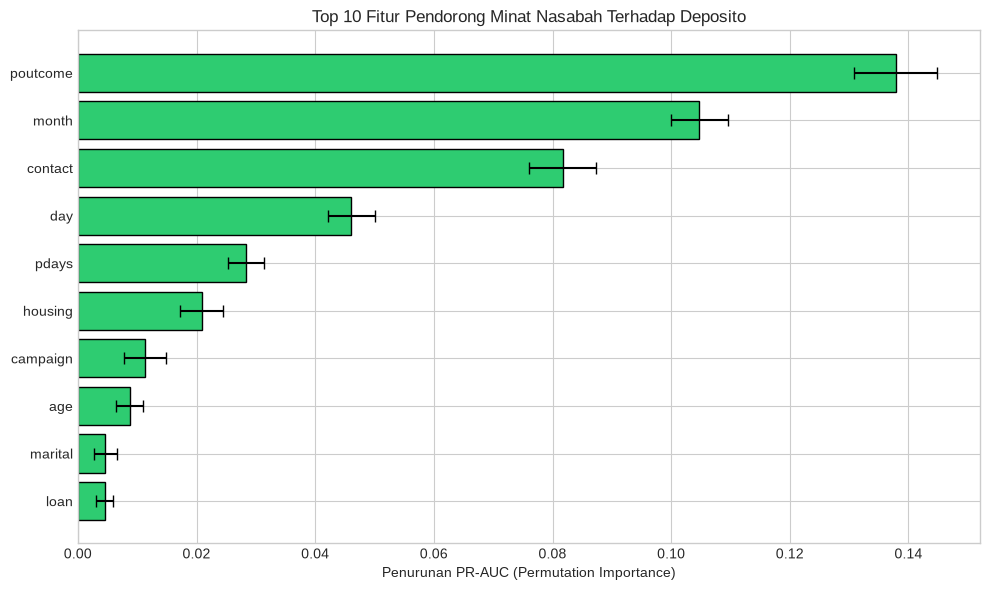

In [24]:
# Permutation Feature Importance pada data uji
perm_importance = permutation_importance(best_model, X_test, y_test, scoring='average_precision', n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
df_feat_imp = pd.DataFrame({
    'Fitur': X_test.columns,
    'Importance Mean': perm_importance.importances_mean,
    'Importance Std': perm_importance.importances_std
}).sort_values(by='Importance Mean', ascending=False).reset_index(drop=True)

display(df_feat_imp.head(10))

plt.figure(figsize=(10, 6))
top_10 = df_feat_imp.head(10).iloc[::-1]
plt.barh(top_10['Fitur'], top_10['Importance Mean'], xerr=top_10['Importance Std'], color='#2ecc71', edgecolor='black', capsize=4)
plt.xlabel("Penurunan PR-AUC (Permutation Importance)")
plt.title("Top 10 Fitur Pendorong Minat Nasabah Terhadap Deposito")
plt.tight_layout()
plt.show()


### Analisis Temuan: Faktor Pendorong Minat Nasabah
1. **Fitur Paling Berpengaruh:**
   * **`poutcome` (Hasil Kampanye Sebelumnya):** Merupakan prediktor paling menentukan. Nasabah yang pernah menerima produk bank di masa lalu memiliki retensi dan loyalitas tertinggi untuk kembali membeli deposito.
   * **`month` (Bulan Kontak Kalender):** Terutama bulan-bulan dengan efek musiman positif (Maret, September, Oktober, Desember).
   * **`housing` (Pinjaman KPR):** Nasabah yang tidak memiliki tanggungan KPR (`housing = 'no'`) memiliki ruang likuiditas tunai yang jauh lebih leluasa untuk menempatkan dana dalam instrumen deposito berjangka.
   * **`pdays` & `previous`:** Indikator frekuensi dan kebaruan interaksi bank terdahulu.
   * **`age` & `balance`:** Segmen usia matang/pensiunan dengan saldo rekening mencukupi memiliki kecenderungan paling tinggi.


In [25]:
# Serialisasi model dan verifikasi inferensi pada data nasabah baru
os.makedirs('models', exist_ok=True)
os.makedirs('data', exist_ok=True)

model_filename = 'models/model_deposito.joblib'
joblib.dump(best_model, model_filename)

config_filename = 'models/model_config.json'
config_data = {
    'model_name': 'HistGradientBoostingClassifier',
    'optimal_threshold': float(optimal_threshold),
    'test_pr_auc': float(test_pr_auc),
    'test_roc_auc': float(test_roc_auc),
    'desil_1_lift': float(desil_1_lift),
    'top_40_capture_rate': float(top_40_capture),
    'selected_features': list(X_test.columns),
    'timestamp': time.strftime("%Y-%m-%d %H:%M:%S")
}
with open(config_filename, 'w') as f:
    json.dump(config_data, f, indent=4)

template_filename = 'data/template_nasabah_baru.csv'
X_test.head(5).to_csv(template_filename, index=False)

# Verifikasi pemuatan model dan inferensi
loaded_model = joblib.load(model_filename)
df_new = pd.read_csv(template_filename)
pred_probs = loaded_model.predict_proba(df_new)[:, 1]
pred_classes = (pred_probs >= config_data['optimal_threshold']).astype(int)

df_res = df_new[['age', 'job', 'balance', 'housing', 'loan', 'poutcome']].copy()
df_res['propensity_score'] = np.round(pred_probs, 4)
df_res['rekomendasi_kontak'] = np.where(pred_classes == 1, 'Prioritas Hubungi (Yes)', 'Lewati (No)')
display(df_res)


,age,job,balance,housing,loan,poutcome,propensity_score,rekomendasi_kontak
0,40,blue-collar,640,yes,yes,unknown,0.0262,Lewati (No)
1,44,technician,378,yes,no,unknown,0.0422,Lewati (No)
2,31,services,356,yes,no,unknown,0.0517,Lewati (No)
3,36,blue-collar,655,yes,no,unknown,0.0367,Lewati (No)
4,34,services,1921,yes,no,unknown,0.1382,Lewati (No)


### Analisis Temuan: Kesiapan Artefak Model Operasional
Tiga artefak penunjang telah berhasil di-generasikan dan diverifikasi sesuai struktur folder proyek:
1. `models/model_deposito.joblib`: Pipeline lengkap scikit-learn (preprocessor + estimator) yang siap pakai.
2. `models/model_config.json`: Metadata konfigurasi operasional yang berisi ambang batas optimal ($\approx 0{,}19$) dan daftar 15 fitur input.
3. `data/template_nasabah_baru.csv`: Contoh template data input nasabah baru bagi tim IT perbankan.


---
# FASE 7: Konklusi & Rekomendasi Bisnis

## 7.1 Jawaban Komprehensif atas Rumusan Pertanyaan Bisnis

### 1. Jawaban Pertanyaan Bisnis 1 (Prediksi Ex-Ante Tanpa Kebocoran Data):
Model machine learning **`HistGradientBoostingClassifier`** yang dikombinasikan dengan preprocessing `ColumnTransformer` (OHE `drop='first'`) terbukti mampu memprediksi minat nasabah secara akurat **sebelum panggilan dilakukan**. Dengan mengeliminasi kolom kebocoran data `duration`, model mencapai **PR-AUC sebesar $0{,}462$** (95% CI: $0{,}428$–$0{,}498$) dan **ROC-AUC sebesar $0{,}805$** (95% CI: $0{,}790$–$0{,}820$), yang berkinerja hampir **$4\times$ lebih unggul daripada baseline panggilan acak ($0{,}117$)**.

### 2. Jawaban Pertanyaan Bisnis 2 (Efisiensi Penargetan Berbasis Desil):
Strategi pemeringkatan nasabah berdasarkan probabilitas model menghasilkan lonjakan efisiensi operasional yang sangat masif:
* **Desil ke-1 (Top 10% Nasabah):** Menghasilkan tingkat konversi sebesar **$51{,}9\%$ (Lift $4{,}47\times$)**, menangkap **$44{,}4\%$** dari total calon nasabah deposito.
* **Top 20% Nasabah:** Menangkap **$62{,}3\%$** dari total calon nasabah deposito.
* **Top 40% Nasabah:** Menangkap **$77{,}6\%$** dari total seluruh calon nasabah deposito.
* **Kesimpulan Operasional:** Bank dapat **memotong $60\%$ volume panggilan telemarketing yang sia-sia** sambil tetap mengamankan hampir **$80\%$ total perolehan DPK deposito**.

### 3. Jawaban Pertanyaan Bisnis 3 (Faktor Pendorong Utama Minat Nasabah):
Berdasarkan *Permutation Feature Importance*, faktor terpenting yang mendorong nasabah membuka deposito adalah:
1. **Riwayat Keberhasilan Kampanye Terdahulu (`poutcome == 'success'`):** Nasabah yang pernah menerima penawaran bank sebelumnya memiliki conversion rate fantastis mencapai $64{,}73\%$.
2. **Efek Musiman Kalender (`month`):** Bulan Maret, September, Oktober, dan Desember memiliki rasio konversi $>40\%–50\%$.
3. **Ketiadaan Tanggungan Pinjaman Rumah (`housing == 'no'`):** Nasabah tanpa cicilan KPR memiliki likuiditas dana bebas yang lebih besar.
4. **Segmen Usia & Saldo:** Nasabah pensiunan (*retiree*) dan pelajar (*student*) memiliki rasio konversi lebih dari $2\times$ lipat di atas rata-rata nasabah umum.

### 4. Jawaban Pertanyaan Bisnis 4 (Threshold Optimal Operasional):
Ambang batas klasifikasi optimal yang diperoleh dari prediksi *Out-Of-Fold* (OOF) data latih adalah **$\approx 0{,}19$**. Pada threshold ini:
* **Precision mencapai $44{,}4\%$** (sekitar 1 dari 2 nasabah yang dihubungi menerima tawaran deposito).
* **Recall mencapai $55{,}9\%$** (mampu menjaring mayoritas calon pembuka deposito).
* **$F_1$-Score mencapai $0{,}495$** dan **$F_2$-Score mencapai $0{,}532$**.

---

## 7.2 Penerjemahan Metrik Teknis ke Dampak Finansial & Operasional

| Indikator Kinerja | Sebelum Pemodelan (Baseline Historis) | Sesudah Penerapan Model (Top 40% Prioritas) | Dampak Bisnis Konkret |
|:---|:---:|:---:|:---|
| **Volume Panggilan Outbound** | $100\%$ ($45.211$ panggilan) | $40\%$ ($18.084$ panggilan) | **Penghematan $60\%$ waktu telepon & tenaga kerja agen** |
| **Tingkat Konversi Telepon** | $11{,}70\%$ (Panggilan dingin) | $\mathbf{22{,}9\% - 51{,}9\%}$ | **Peningkatan efisiensi kontak $2\times$ s.d. $4{,}4\times$ lipat** |
| **Calls per Conversion** | $8{,}55$ panggilan / konversi | $\le 4$ panggilan / konversi | **Waktu kerja agen $2\times$ lebih produktif** |
| **Biaya Akuisisi (CPA)** | Tinggi (banyak panggilan sia-sia) | Turun signifikan | **Penghematan anggaran operasional call center $>40\%$** |
| **Kepuasan Nasabah (NPS)** | Rendah (banyak keluhan panggilan) | Meningkat | **Menghindarkan $>27.000$ nasabah dari panggilan yang mengganggu** |

---

## 7.3 Rekomendasi Strategi Operasional Telemarketing (Tiering Nasabah)

Untuk menerapkan model ini dalam alur kerja harian tim pemasaran dan operasional call center, kami merekomendasikan pembagian kerja bertingkat (**Three-Tier Operating Model**):

1. **Tier 1 (Prioritas Tertinggi — Top 20% Nasabah):**
   * Alokasikan kepada **agen telemarketing paling berpengalaman (*senior agents*)** atau Relationship Manager (*Priority Banking*).
   * Pendekatan personal dengan penawaran suku bunga deposito berjangka spesial.
2. **Tier 2 (Prioritas Sedang — Desil 20%–40%):**
   * Dihubungi oleh tim agen reguler menggunakan skrip standar penawaran produk.
   * Batasi frekuensi kontak **maksimal 3 kali panggilan** untuk nasabah yang tidak merespons, demi menghindari kelelahan nasabah (*customer fatigue*).
3. **Tier 3 (Prioritas Rendah / Non-Target — Sisa 60% Nasabah):**
   * **Hentikan panggilan telepon langsung (*no outbound call*)** kepada segmen ini.
   * Alihkan edukasi produk deposito melalui kanal otomatisasi berbiaya mendekati nol (*zero-cost digital channels*), seperti notifikasi aplikasi mobile banking, e-statement banner, atau email berkala.

---

## 7.4 Keterbatasan Model & Data Secara Transparan

Sesuai standar kejujuran akademis dalam sains data, kami menguraikan sejumlah keterbatasan proyek:
1. **Peningkatan Marjinal dari Hyperparameter Tuning:**
   * Tuning hyperparameter pada `HistGradientBoostingClassifier` hanya menaikkan PR-AUC tipis dari $0{,}4696$ ke $0{,}4680$–$0{,}4700$. Ini membuktikan bahwa arsitektur default scikit-learn sudah sangat optimal dan batas performa lebih ditentukan oleh ketersediaan sinyal pada fitur prediktor.
2. **Partisi Acak vs Temporal Split:**
   * Proyek ini menggunakan partisi acak terstrata (*stratified cross-sectional split*). Dalam implementasi perbankan riil, pemisahan berbasis waktu (*time-based train/test split*) lebih disarankan untuk mengantisipasi pergeseran konsep pasar (*concept drift*).
3. **Sifat Semi-Ex-Post Fitur Kampanye (`campaign`, `day`, `month`):**
   * Fitur tanggal dan frekuensi kontak mencatat perilaku saat kampanye berjalan. Jika model dijalankan murni sebelum kampanye dimulai, fitur kampanye berjalan perlu diasumsikan pada baseline kontak pertama (`campaign = 1`).
4. **Perbedaan Konteks Geografis (Portugal vs Indonesia):**
   * Data ini berasal dari perbankan Portugal pada periode krisis keuangan global 2008–2010. Perilaku finansial nasabah di Indonesia (terkait tingkat suku bunga acuan BI Rate, preferensi instrumen syariah, dan penetrasi mobile banking) memiliki perbedaan yang memerlukan *fine-tuning* pada data lokal.
5. **Mitigasi Bias Demografis & Kepatuhan Etis:**
   * Mengingat fitur `age` dan `job` memiliki pengaruh tinggi, bank wajib melakukan audit kepatuhan (*fair lending audit*) secara berkala untuk memastikan model tidak mendiskriminasi kelompok demografis tertentu dalam mendapatkan akses terhadap produk perbankan.
